<a href="https://colab.research.google.com/github/eh3285/audit-home/blob/main/lightgbm/emma/LightGBM_phase1AB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Home Credit Default Risk Prediction

# Phase 1A/1B — no-retrain audit notebook


## Reconstruct only the frozen model inputs — no retraining

Run the input-loading and eight-file feature-engineering cells below. They reproduce the 486-column numeric feature matrix consumed by the original LightGBM; they do **not** train or evaluate a new model. The Phase 0 models, predictions, and schema are loaded **directly from the raw CSV directory** (normally `/content`), unless `HOME_CREDIT_PHASE0_DIR` is set.

### Input setup and reproducibility

Upload the eight Home Credit competition CSVs **and all nine required Phase 0 files to this notebook**, using the same Colab Files panel.

New reconstruction metadata is saved under `audit_artifacts/phase1/reconstruction/`.


In [1]:
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError
import json
import os
import platform
import random
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PolynomialFeatures, MinMaxScaler
from sklearn.ensemble import RandomForestClassifier

AUDIT_SEED = 42
random.seed(AUDIT_SEED)
np.random.seed(AUDIT_SEED)

REQUIRED_HOME_CREDIT_FILES = [
    "application_train.csv",
    "application_test.csv",
    "previous_application.csv",
    "bureau.csv",
    "bureau_balance.csv",
    "POS_CASH_balance.csv",
    "installments_payments.csv",
    "credit_card_balance.csv",
]
candidate_dirs = [
    os.environ.get("HOME_CREDIT_DATA_DIR"),
    "/kaggle/input/home-credit-default-risk",
    "/content",
    "./data/home-credit-default-risk",
    "./data",
    "../input/home-credit-default-risk",
    ".",
]
candidate_dirs = [Path(p).expanduser() for p in candidate_dirs if p]
complete_dirs = [p for p in candidate_dirs
                 if all((p / name).is_file() for name in REQUIRED_HOME_CREDIT_FILES)]
default_dir = str(complete_dirs[0].resolve()) if complete_dirs else None

AUDIT_OUTPUT_DIR = Path(
    os.environ.get("HOME_CREDIT_PHASE1_RECON_DIR", "audit_artifacts/phase1/reconstruction")
).expanduser()
AUDIT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
# Hashing all eight files takes extra time and I/O; enable for exact data checksums.
HASH_RAW_FILES = False
# Preserve the original exploratory Random Forest as an opt-in, not a Phase 0 input.
RUN_LEGACY_RANDOM_FOREST = False
# Optional separate step: refit a full-data model for an unlabeled Kaggle submission.
TRAIN_FULL_SUBMISSION_MODEL = False
# Persist each fold's model to allow precisely reproducible later SHAP experiments.
SAVE_FOLD_MODELS = True

def _package_version(name):
    try:
        return version(name)
    except PackageNotFoundError:
        return "not installed"

environment_manifest = {
    "seed": AUDIT_SEED,
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "package_versions": {name: _package_version(name) for name in
                         ["numpy", "pandas", "scikit-learn", "lightgbm", "scipy", "shap"]},
    "input_directory": default_dir,
    "expected_input_files": REQUIRED_HOME_CREDIT_FILES,
}
(AUDIT_OUTPUT_DIR / "environment.json").write_text(
    json.dumps(environment_manifest, indent=2), encoding="utf-8"
)
print("Audit output:", AUDIT_OUTPUT_DIR.resolve())
print("Detected data directory:", default_dir or "NOT FOUND")
if default_dir is None:
    print("Set HOME_CREDIT_DATA_DIR to a directory containing all eight CSVs, then rerun.")


Audit output: /content/audit_artifacts/phase1/reconstruction
Detected data directory: /content


### **Step 2: Load the Datasets**
Use `pandas` to load the datasets:

In [2]:
if default_dir is None:
    raise FileNotFoundError("Eight Home Credit CSVs not found. Configure HOME_CREDIT_DATA_DIR in 0A.")

app_train = pd.read_csv(os.path.join(default_dir,'application_train.csv'))
app_test = pd.read_csv(os.path.join(default_dir,'application_test.csv'))

# Display basic information about the dataset
print("Training set shape:", app_train.shape)
print("Testing set shape:", app_test.shape)

app_test.head()


Training set shape: (307511, 122)
Testing set shape: (48744, 121)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100001,Cash loans,F,N,Y,0,135000.0,568800.0,20560.5,450000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
1,100005,Cash loans,M,N,Y,0,99000.0,222768.0,17370.0,180000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,3.0
2,100013,Cash loans,M,Y,Y,0,202500.0,663264.0,69777.0,630000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,1.0,4.0
3,100028,Cash loans,F,N,Y,2,315000.0,1575000.0,49018.5,1575000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,3.0
4,100038,Cash loans,M,Y,N,1,180000.0,625500.0,32067.0,625500.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


### 0B. Verify the raw applicant population and preserve audit attributes

The competition's labeled training set provides the audit population. The
unlabeled test set cannot be used to calculate accuracy or fairness metrics.
The saved `audit_reference_raw` table is keyed by `SK_ID_CURR`; none of these
columns is substituted for the actual engineered LightGBM feature table.


In [3]:
import hashlib

if default_dir is None:
    raise FileNotFoundError(
        "Missing Home Credit CSVs. Set HOME_CREDIT_DATA_DIR to the folder "
        "containing all eight original competition CSVs, then rerun 0A."
    )

def _file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for chunk in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

raw_file_inventory = pd.DataFrame([
    {
        "filename": name,
        "size_bytes": (Path(default_dir) / name).stat().st_size,
        "sha256": _file_sha256(Path(default_dir) / name) if HASH_RAW_FILES else None,
    }
    for name in REQUIRED_HOME_CREDIT_FILES
])
raw_file_inventory.to_csv(AUDIT_OUTPUT_DIR / "raw_file_inventory.csv", index=False)

assert "TARGET" in app_train.columns and "TARGET" not in app_test.columns
assert app_train["SK_ID_CURR"].notna().all() and app_test["SK_ID_CURR"].notna().all()
assert app_train["SK_ID_CURR"].is_unique and app_test["SK_ID_CURR"].is_unique
assert not set(app_train["SK_ID_CURR"]).intersection(app_test["SK_ID_CURR"]), (
    "Labeled and competition-test IDs overlap."
)
assert app_train["TARGET"].notna().all()
assert set(app_train["TARGET"].unique()).issubset({0, 1})

# Freeze raw attributes BEFORE the optional exploratory cells encode or modify them.
AUDIT_RAW_ATTRIBUTES = [
    "CODE_GENDER", "DAYS_BIRTH", "NAME_EDUCATION_TYPE",
    "NAME_FAMILY_STATUS", "NAME_INCOME_TYPE", "AMT_INCOME_TOTAL",
    "AMT_CREDIT", "AMT_ANNUITY", "DAYS_EMPLOYED", "EXT_SOURCE_1",
    "EXT_SOURCE_2", "EXT_SOURCE_3", "FLAG_OWN_CAR",
    "FLAG_OWN_REALTY", "REGION_RATING_CLIENT",
]
audit_reference_raw = app_train[
    ["SK_ID_CURR"] + [col for col in AUDIT_RAW_ATTRIBUTES if col in app_train]
].copy()

raw_summary = {
    "train_rows": int(len(app_train)),
    "competition_test_rows": int(len(app_test)),
    "train_columns_including_target": int(app_train.shape[1]),
    "test_columns": int(app_test.shape[1]),
    "label_1_count": int(app_train["TARGET"].sum()),
    "label_1_rate": float(app_train["TARGET"].mean()),
    "unique_train_ids": int(app_train["SK_ID_CURR"].nunique()),
    "unique_test_ids": int(app_test["SK_ID_CURR"].nunique()),
    "days_employed_365243_train": int((app_train["DAYS_EMPLOYED"] == 365243).sum()),
    "days_employed_365243_test": int((app_test["DAYS_EMPLOYED"] == 365243).sum()),
    "protected_or_proxy_attributes_preserved": list(audit_reference_raw.columns[1:]),
}
(AUDIT_OUTPUT_DIR / "raw_population_summary.json").write_text(
    json.dumps(raw_summary, indent=2), encoding="utf-8"
)
print("Labeled applicants:", f'{raw_summary["train_rows"]:,}')
print("Competition-test applicants:", f'{raw_summary["competition_test_rows"]:,}')
print("TARGET=1 prevalence:", f'{raw_summary["label_1_rate"]:.3%}')
display(raw_file_inventory[["filename", "size_bytes"]])
display(app_train.isna().mean().sort_values(ascending=False).head(12).rename("missing_fraction").to_frame())


Labeled applicants: 307,511
Competition-test applicants: 48,744
TARGET=1 prevalence: 8.073%


,filename,size_bytes
0,application_train.csv,166133370
1,application_test.csv,26567651
2,previous_application.csv,404973293
3,bureau.csv,170016717
4,bureau_balance.csv,375592889
5,POS_CASH_balance.csv,392703158
6,installments_payments.csv,723118349
7,credit_card_balance.csv,424582605


,missing_fraction
COMMONAREA_AVG,0.698723
COMMONAREA_MODE,0.698723
COMMONAREA_MEDI,0.698723
NONLIVINGAPARTMENTS_MEDI,0.694330
NONLIVINGAPARTMENTS_MODE,0.694330
NONLIVINGAPARTMENTS_AVG,0.694330
FONDKAPREMONT_MODE,0.683862
LIVINGAPARTMENTS_AVG,0.683550
LIVINGAPARTMENTS_MEDI,0.683550
LIVINGAPARTMENTS_MODE,0.683550


## Original eight-file feature engineering (unchanged)

These functions reproduce the preprocessing consumed by the final LightGBM.
The audit's extra metadata collection does **not** change feature values.


In [4]:
def get_balance_data():
    pos_dtype = {
        'SK_ID_PREV':np.uint32, 'SK_ID_CURR':np.uint32, 'MONTHS_BALANCE':np.int32, 'SK_DPD':np.int32,
        'SK_DPD_DEF':np.int32, 'CNT_INSTALMENT':np.float32,'CNT_INSTALMENT_FUTURE':np.float32
    }

    install_dtype = {
        'SK_ID_PREV':np.uint32, 'SK_ID_CURR':np.uint32, 'NUM_INSTALMENT_NUMBER':np.int32, 'NUM_INSTALMENT_VERSION':np.float32,
        'DAYS_INSTALMENT':np.float32, 'DAYS_ENTRY_PAYMENT':np.float32, 'AMT_INSTALMENT':np.float32, 'AMT_PAYMENT':np.float32
    }

    card_dtype = {
        'SK_ID_PREV':np.uint32, 'SK_ID_CURR':np.uint32, 'MONTHS_BALANCE':np.int16,
        'AMT_CREDIT_LIMIT_ACTUAL':np.int32, 'CNT_DRAWINGS_CURRENT':np.int32, 'SK_DPD':np.int32,'SK_DPD_DEF':np.int32,
        'AMT_BALANCE':np.float32, 'AMT_DRAWINGS_ATM_CURRENT':np.float32, 'AMT_DRAWINGS_CURRENT':np.float32,
        'AMT_DRAWINGS_OTHER_CURRENT':np.float32, 'AMT_DRAWINGS_POS_CURRENT':np.float32, 'AMT_INST_MIN_REGULARITY':np.float32,
        'AMT_PAYMENT_CURRENT':np.float32, 'AMT_PAYMENT_TOTAL_CURRENT':np.float32, 'AMT_RECEIVABLE_PRINCIPAL':np.float32,
        'AMT_RECIVABLE':np.float32, 'AMT_TOTAL_RECEIVABLE':np.float32, 'CNT_DRAWINGS_ATM_CURRENT':np.float32,
        'CNT_DRAWINGS_OTHER_CURRENT':np.float32, 'CNT_DRAWINGS_POS_CURRENT':np.float32, 'CNT_INSTALMENT_MATURE_CUM':np.float32
    }

    pos_bal = pd.read_csv(os.path.join(default_dir,'POS_CASH_balance.csv'), dtype=pos_dtype)
    install = pd.read_csv(os.path.join(default_dir,'installments_payments.csv'), dtype=install_dtype)
    card_bal = pd.read_csv(os.path.join(default_dir, 'credit_card_balance.csv'), dtype=card_dtype)

    return pos_bal, install, card_bal

# Loaded once by get_dataset() in the final LightGBM pipeline.

In [5]:
def get_apps_processed(apps):
    """
    feature engineering for apps
    """

    # 1.EXT_SOURCE
    apps['APPS_EXT_SOURCE_MEAN'] = apps[['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']].mean(axis = 1)
    apps['APPS_EXT_SOURCE_STD'] = apps[['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']].std(axis=1)
    apps['APPS_EXT_SOURCE_STD'] = apps['APPS_EXT_SOURCE_STD'].fillna(apps['APPS_EXT_SOURCE_STD'].mean())

    # AMT_CREDIT
    apps['APPS_ANNUITY_CREDIT_RATIO'] = apps['AMT_ANNUITY']/apps['AMT_CREDIT']
    apps['APPS_GOODS_CREDIT_RATIO'] = apps['AMT_GOODS_PRICE']/apps['AMT_CREDIT']

    # AMT_INCOME_TOTAL
    apps['APPS_ANNUITY_INCOME_RATIO'] = apps['AMT_ANNUITY']/apps['AMT_INCOME_TOTAL']
    apps['APPS_CREDIT_INCOME_RATIO'] = apps['AMT_CREDIT']/apps['AMT_INCOME_TOTAL']
    apps['APPS_GOODS_INCOME_RATIO'] = apps['AMT_GOODS_PRICE']/apps['AMT_INCOME_TOTAL']
    apps['APPS_CNT_FAM_INCOME_RATIO'] = apps['AMT_INCOME_TOTAL']/apps['CNT_FAM_MEMBERS']

    # DAYS_BIRTH, DAYS_EMPLOYED
    apps['APPS_EMPLOYED_BIRTH_RATIO'] = apps['DAYS_EMPLOYED']/apps['DAYS_BIRTH']
    apps['APPS_INCOME_EMPLOYED_RATIO'] = apps['AMT_INCOME_TOTAL']/apps['DAYS_EMPLOYED']
    apps['APPS_INCOME_BIRTH_RATIO'] = apps['AMT_INCOME_TOTAL']/apps['DAYS_BIRTH']
    apps['APPS_CAR_BIRTH_RATIO'] = apps['OWN_CAR_AGE'] / apps['DAYS_BIRTH']
    apps['APPS_CAR_EMPLOYED_RATIO'] = apps['OWN_CAR_AGE'] / apps['DAYS_EMPLOYED']

    return apps

In [6]:
def get_prev_processed(prev):
    """
    feature engineering
    for previous application credit history
    """
    prev['PREV_CREDIT_DIFF'] = prev['AMT_APPLICATION'] - prev['AMT_CREDIT']
    prev['PREV_GOODS_DIFF'] = prev['AMT_APPLICATION'] - prev['AMT_GOODS_PRICE']
    prev['PREV_CREDIT_APPL_RATIO'] = prev['AMT_CREDIT']/prev['AMT_APPLICATION']
    prev['PREV_GOODS_APPL_RATIO'] = prev['AMT_GOODS_PRICE']/prev['AMT_APPLICATION']

    prev['DAYS_FIRST_DRAWING'] = prev['DAYS_FIRST_DRAWING'].replace(365243, np.nan)
    prev['DAYS_FIRST_DUE'] = prev['DAYS_FIRST_DUE'].replace(365243, np.nan)
    prev['DAYS_LAST_DUE_1ST_VERSION'] = prev['DAYS_LAST_DUE_1ST_VERSION'].replace(365243, np.nan)
    prev['DAYS_LAST_DUE'] = prev['DAYS_LAST_DUE'].replace(365243, np.nan)
    prev['DAYS_TERMINATION'] = prev['DAYS_TERMINATION'].replace(365243, np.nan)

    prev['PREV_DAYS_LAST_DUE_DIFF'] = prev['DAYS_LAST_DUE_1ST_VERSION'] - prev['DAYS_LAST_DUE']

    all_pay = prev['AMT_ANNUITY'] * prev['CNT_PAYMENT']
    prev['PREV_INTERESTS_RATE'] = (all_pay/prev['AMT_CREDIT'] - 1)/prev['CNT_PAYMENT']

    return prev

def get_prev_amt_agg(prev):
    """
    feature enginnering for the previous credit application
    """
    agg_dict = {
      'SK_ID_CURR':['count'],
      'AMT_CREDIT':['mean', 'max', 'sum'],
      'AMT_ANNUITY':['mean', 'max', 'sum'],
      'AMT_APPLICATION':['mean', 'max', 'sum'],
      'AMT_DOWN_PAYMENT':['mean', 'max', 'sum'],
      'AMT_GOODS_PRICE':['mean', 'max', 'sum'],
      'RATE_DOWN_PAYMENT': ['min', 'max', 'mean'],
      'DAYS_DECISION': ['min', 'max', 'mean'],
      'CNT_PAYMENT': ['mean', 'sum'],

      'PREV_CREDIT_DIFF':['mean', 'max', 'sum'],
      'PREV_CREDIT_APPL_RATIO':['mean', 'max'],
      'PREV_GOODS_DIFF':['mean', 'max', 'sum'],
      'PREV_GOODS_APPL_RATIO':['mean', 'max'],
      'PREV_DAYS_LAST_DUE_DIFF':['mean', 'max', 'sum'],
      'PREV_INTERESTS_RATE':['mean', 'max']
    }

    prev_group = prev.groupby('SK_ID_CURR')
    prev_amt_agg = prev_group.agg(agg_dict)
    prev_amt_agg.columns = ["PREV_"+ "_".join(x).upper() for x in prev_amt_agg.columns.ravel()]

    return prev_amt_agg

def get_prev_refused_appr_agg(prev):
    """
    PREV_APPROVED_COUNT : Credit application approved count
    PREV_REFUSED_COUNT :  Credit application refused count
    """
    prev_refused_appr_group = prev[prev['NAME_CONTRACT_STATUS'].isin(['Approved', 'Refused'])].groupby([ 'SK_ID_CURR', 'NAME_CONTRACT_STATUS'])
    prev_refused_appr_agg = prev_refused_appr_group['SK_ID_CURR'].count().unstack()
    prev_refused_appr_agg.columns = ['PREV_APPROVED_COUNT', 'PREV_REFUSED_COUNT' ]
    prev_refused_appr_agg = prev_refused_appr_agg.fillna(0)
    return prev_refused_appr_agg


def get_prev_days365_agg(prev):
    """
    DAYS_DESCISION means How many days have been take since the previous credit application made.
    Somehow this feature is important.
    """
    cond_days365 = prev['DAYS_DECISION'] > -365
    prev_days365_group = prev[cond_days365].groupby('SK_ID_CURR')
    agg_dict = {
      'SK_ID_CURR':['count'],
      'AMT_CREDIT':['mean', 'max', 'sum'],
      'AMT_ANNUITY':['mean', 'max', 'sum'],
      'AMT_APPLICATION':['mean', 'max', 'sum'],
      'AMT_DOWN_PAYMENT':['mean', 'max', 'sum'],
      'AMT_GOODS_PRICE':['mean', 'max', 'sum'],
      'RATE_DOWN_PAYMENT': ['min', 'max', 'mean'],
      'DAYS_DECISION': ['min', 'max', 'mean'],
      'CNT_PAYMENT': ['mean', 'sum'],

      'PREV_CREDIT_DIFF':['mean', 'max', 'sum'],
      'PREV_CREDIT_APPL_RATIO':['mean', 'max'],
      'PREV_GOODS_DIFF':['mean', 'max', 'sum'],
      'PREV_GOODS_APPL_RATIO':['mean', 'max'],
      'PREV_DAYS_LAST_DUE_DIFF':['mean', 'max', 'sum'],
      'PREV_INTERESTS_RATE':['mean', 'max']
    }

    prev_days365_agg = prev_days365_group.agg(agg_dict)

    # multi index
    prev_days365_agg.columns = ["PREV_D365_"+ "_".join(x).upper() for x in prev_days365_agg.columns.ravel()]

    return prev_days365_agg

def get_prev_agg(prev):
    prev = get_prev_processed(prev)
    prev_amt_agg = get_prev_amt_agg(prev)
    prev_refused_appr_agg = get_prev_refused_appr_agg(prev)
    prev_days365_agg = get_prev_days365_agg(prev)

    # prev_amt_agg
    prev_agg = prev_amt_agg.merge(prev_refused_appr_agg, on='SK_ID_CURR', how='left')
    prev_agg = prev_agg.merge(prev_days365_agg, on='SK_ID_CURR', how='left')
    # SK_ID_CURR APPROVED_COUNT REFUSED_COUNT
    prev_agg['PREV_REFUSED_RATIO'] = prev_agg['PREV_REFUSED_COUNT']/prev_agg['PREV_SK_ID_CURR_COUNT']
    prev_agg['PREV_APPROVED_RATIO'] = prev_agg['PREV_APPROVED_COUNT']/prev_agg['PREV_SK_ID_CURR_COUNT']
    # 'PREV_REFUSED_COUNT', 'PREV_APPROVED_COUNT' drop
    prev_agg = prev_agg.drop(['PREV_REFUSED_COUNT', 'PREV_APPROVED_COUNT'], axis=1)

    return prev_agg

In [7]:
def get_bureau_processed(bureau):
    bureau['BUREAU_ENDDATE_FACT_DIFF'] = bureau['DAYS_CREDIT_ENDDATE'] - bureau['DAYS_ENDDATE_FACT']
    bureau['BUREAU_CREDIT_FACT_DIFF'] = bureau['DAYS_CREDIT'] - bureau['DAYS_ENDDATE_FACT']
    bureau['BUREAU_CREDIT_ENDDATE_DIFF'] = bureau['DAYS_CREDIT'] - bureau['DAYS_CREDIT_ENDDATE']
    bureau['BUREAU_CREDIT_DEBT_RATIO']=bureau['AMT_CREDIT_SUM_DEBT']/bureau['AMT_CREDIT_SUM']
    bureau['BUREAU_CREDIT_DEBT_DIFF'] = bureau['AMT_CREDIT_SUM_DEBT'] - bureau['AMT_CREDIT_SUM']

    bureau['BUREAU_IS_DPD'] = bureau['CREDIT_DAY_OVERDUE'].apply(lambda x: 1 if x > 0 else 0)
    bureau['BUREAU_IS_DPD_OVER120'] = bureau['CREDIT_DAY_OVERDUE'].apply(lambda x: 1 if x >120 else 0)

    return bureau

def get_bureau_day_amt_agg(bureau):
    bureau_agg_dict = {
    'SK_ID_BUREAU':['count'],
    'DAYS_CREDIT':['min', 'max', 'mean'],
    'CREDIT_DAY_OVERDUE':['min', 'max', 'mean'],
    'DAYS_CREDIT_ENDDATE':['min', 'max', 'mean'],
    'DAYS_ENDDATE_FACT':['min', 'max', 'mean'],
    'AMT_CREDIT_MAX_OVERDUE': ['max', 'mean'],
    'AMT_CREDIT_SUM': ['max', 'mean', 'sum'],
    'AMT_CREDIT_SUM_DEBT': ['max', 'mean', 'sum'],
    'AMT_CREDIT_SUM_OVERDUE': ['max', 'mean', 'sum'],
    'AMT_ANNUITY': ['max', 'mean', 'sum'],

    'BUREAU_ENDDATE_FACT_DIFF':['min', 'max', 'mean'],
    'BUREAU_CREDIT_FACT_DIFF':['min', 'max', 'mean'],
    'BUREAU_CREDIT_ENDDATE_DIFF':['min', 'max', 'mean'],
    'BUREAU_CREDIT_DEBT_RATIO':['min', 'max', 'mean'],
    'BUREAU_CREDIT_DEBT_DIFF':['min', 'max', 'mean'],
    'BUREAU_IS_DPD':['mean', 'sum'],
    'BUREAU_IS_DPD_OVER120':['mean', 'sum']
    }

    bureau_grp = bureau.groupby('SK_ID_CURR')
    bureau_day_amt_agg = bureau_grp.agg(bureau_agg_dict)
    bureau_day_amt_agg.columns = ['BUREAU_'+('_').join(column).upper() for column in bureau_day_amt_agg.columns.ravel()]
    # SK_ID_CURR reset_index()
    bureau_day_amt_agg = bureau_day_amt_agg.reset_index()
    #print('bureau_day_amt_agg shape:', bureau_day_amt_agg.shape)
    return bureau_day_amt_agg

def get_bureau_active_agg(bureau):
    cond_active = bureau['CREDIT_ACTIVE'] == 'Active'
    bureau_active_grp = bureau[cond_active].groupby(['SK_ID_CURR'])
    bureau_agg_dict = {
      'SK_ID_BUREAU':['count'],
      'DAYS_CREDIT':['min', 'max', 'mean'],
      'CREDIT_DAY_OVERDUE':['min', 'max', 'mean'],
      'DAYS_CREDIT_ENDDATE':['min', 'max', 'mean'],
      'DAYS_ENDDATE_FACT':['min', 'max', 'mean'],
      'AMT_CREDIT_MAX_OVERDUE': ['max', 'mean'],
      'AMT_CREDIT_SUM': ['max', 'mean', 'sum'],
      'AMT_CREDIT_SUM_DEBT': ['max', 'mean', 'sum'],
      'AMT_CREDIT_SUM_OVERDUE': ['max', 'mean', 'sum'],
      'AMT_ANNUITY': ['max', 'mean', 'sum'],

      'BUREAU_ENDDATE_FACT_DIFF':['min', 'max', 'mean'],
      'BUREAU_CREDIT_FACT_DIFF':['min', 'max', 'mean'],
      'BUREAU_CREDIT_ENDDATE_DIFF':['min', 'max', 'mean'],
      'BUREAU_CREDIT_DEBT_RATIO':['min', 'max', 'mean'],
      'BUREAU_CREDIT_DEBT_DIFF':['min', 'max', 'mean'],
      'BUREAU_IS_DPD':['mean', 'sum'],
      'BUREAU_IS_DPD_OVER120':['mean', 'sum']
      }

    bureau_active_agg = bureau_active_grp.agg(bureau_agg_dict)
    bureau_active_agg.columns = ['BUREAU_ACT_'+('_').join(column).upper() for column in bureau_active_agg.columns.ravel()]
    bureau_active_agg = bureau_active_agg.reset_index()

    return bureau_active_agg


def get_bureau_bal_agg(bureau, bureau_bal):
    bureau_bal = bureau_bal.merge(bureau[['SK_ID_CURR', 'SK_ID_BUREAU']], on='SK_ID_BUREAU', how='left')
    bureau_bal['BUREAU_BAL_IS_DPD'] = bureau_bal['STATUS'].apply(lambda x: 1 if x in['1','2','3','4','5']  else 0)
    bureau_bal['BUREAU_BAL_IS_DPD_OVER120'] = bureau_bal['STATUS'].apply(lambda x: 1 if x =='5'  else 0)
    bureau_bal_grp = bureau_bal.groupby('SK_ID_CURR')

    bureau_bal_agg_dict = {
        'SK_ID_CURR':['count'],
        'MONTHS_BALANCE':['min', 'max', 'mean'],
        'BUREAU_BAL_IS_DPD':['mean', 'sum'],
        'BUREAU_BAL_IS_DPD_OVER120':['mean', 'sum']
    }

    bureau_bal_agg = bureau_bal_grp.agg(bureau_bal_agg_dict)
    bureau_bal_agg.columns = [ 'BUREAU_BAL_'+('_').join(column).upper() for column in bureau_bal_agg.columns.ravel() ]

    bureau_bal_agg = bureau_bal_agg.reset_index()
    return bureau_bal_agg

def get_bureau_agg(bureau, bureau_bal):
    bureau = get_bureau_processed(bureau)
    bureau_day_amt_agg = get_bureau_day_amt_agg(bureau)
    bureau_active_agg = get_bureau_active_agg(bureau)
    bureau_bal_agg = get_bureau_bal_agg(bureau, bureau_bal)

    bureau_agg = bureau_day_amt_agg.merge(bureau_active_agg, on='SK_ID_CURR', how='left')
    bureau_agg['BUREAU_ACT_IS_DPD_RATIO'] = bureau_agg['BUREAU_ACT_BUREAU_IS_DPD_SUM']/bureau_agg['BUREAU_SK_ID_BUREAU_COUNT']
    bureau_agg['BUREAU_ACT_IS_DPD_OVER120_RATIO'] = bureau_agg['BUREAU_ACT_BUREAU_IS_DPD_OVER120_SUM']/bureau_agg['BUREAU_SK_ID_BUREAU_COUNT']

    bureau_agg = bureau_agg.merge(bureau_bal_agg, on='SK_ID_CURR', how='left')
    #bureau_agg = bureau_agg.merge(bureau_days750_agg, on='SK_ID_CURR', how='left')

    return bureau_agg

In [8]:
def get_pos_bal_agg(pos_bal):
    cond_over_0 = pos_bal['SK_DPD'] > 0
    cond_100 = (pos_bal['SK_DPD'] < 100) & (pos_bal['SK_DPD'] > 0)
    cond_over_100 = (pos_bal['SK_DPD'] >= 100)

    pos_bal['POS_IS_DPD'] = pos_bal['SK_DPD'].apply(lambda x: 1 if x > 0 else 0)
    pos_bal['POS_IS_DPD_UNDER_120'] = pos_bal['SK_DPD'].apply(lambda x:1 if (x > 0) & (x <120) else 0 )
    pos_bal['POS_IS_DPD_OVER_120'] = pos_bal['SK_DPD'].apply(lambda x:1 if x >= 120 else 0)

    pos_bal_grp = pos_bal.groupby('SK_ID_CURR')
    pos_bal_agg_dict = {
        'SK_ID_CURR':['count'],
        'MONTHS_BALANCE':['min', 'mean', 'max'],
        'SK_DPD':['min', 'max', 'mean', 'sum'],
        'CNT_INSTALMENT':['min', 'max', 'mean', 'sum'],
        'CNT_INSTALMENT_FUTURE':['min', 'max', 'mean', 'sum'],

        'POS_IS_DPD':['mean', 'sum'],
        'POS_IS_DPD_UNDER_120':['mean', 'sum'],
        'POS_IS_DPD_OVER_120':['mean', 'sum']
    }

    pos_bal_agg = pos_bal_grp.agg(pos_bal_agg_dict)

    pos_bal_agg.columns = [('POS_')+('_').join(column).upper() for column in pos_bal_agg.columns.ravel()]

    cond_months = pos_bal['MONTHS_BALANCE'] > -20
    pos_bal_m20_grp = pos_bal[cond_months].groupby('SK_ID_CURR')
    pos_bal_m20_agg_dict = {
        'SK_ID_CURR':['count'],
        'MONTHS_BALANCE':['min', 'mean', 'max'],
        'SK_DPD':['min', 'max', 'mean', 'sum'],
        'CNT_INSTALMENT':['min', 'max', 'mean', 'sum'],
        'CNT_INSTALMENT_FUTURE':['min', 'max', 'mean', 'sum'],

        'POS_IS_DPD':['mean', 'sum'],
        'POS_IS_DPD_UNDER_120':['mean', 'sum'],
        'POS_IS_DPD_OVER_120':['mean', 'sum']
    }

    pos_bal_m20_agg = pos_bal_m20_grp.agg(pos_bal_m20_agg_dict)

    pos_bal_m20_agg.columns = [('POS_M20')+('_').join(column).upper() for column in pos_bal_m20_agg.columns.ravel()]
    pos_bal_agg = pos_bal_agg.merge(pos_bal_m20_agg, on='SK_ID_CURR', how='left')
    pos_bal_agg = pos_bal_agg.reset_index()


    return pos_bal_agg

In [9]:
def get_install_agg(install):
    install['AMT_DIFF'] = install['AMT_INSTALMENT'] - install['AMT_PAYMENT']
    install['AMT_RATIO'] =  (install['AMT_PAYMENT'] +1)/ (install['AMT_INSTALMENT'] + 1)
    install['SK_DPD'] = install['DAYS_ENTRY_PAYMENT'] - install['DAYS_INSTALMENT']

    install['INS_IS_DPD'] = install['SK_DPD'].apply(lambda x: 1 if x > 0 else 0)
    install['INS_IS_DPD_UNDER_120'] = install['SK_DPD'].apply(lambda x:1 if (x > 0) & (x <120) else 0 )
    install['INS_IS_DPD_OVER_120'] = install['SK_DPD'].apply(lambda x:1 if x >= 120 else 0)

    install_grp = install.groupby('SK_ID_CURR')

    install_agg_dict = {
        'SK_ID_CURR':['count'],
        'NUM_INSTALMENT_VERSION':['nunique'],
        'DAYS_ENTRY_PAYMENT':['mean', 'max', 'sum'],
        'DAYS_INSTALMENT':['mean', 'max', 'sum'],
        'AMT_INSTALMENT':['mean', 'max', 'sum'],
        'AMT_PAYMENT':['mean', 'max','sum'],

        'AMT_DIFF':['mean','min', 'max','sum'],
        'AMT_RATIO':['mean', 'max'],
        'SK_DPD':['mean', 'min', 'max'],
        'INS_IS_DPD':['mean', 'sum'],
        'INS_IS_DPD_UNDER_120':['mean', 'sum'],
        'INS_IS_DPD_OVER_120':['mean', 'sum']
    }

    install_agg = install_grp.agg(install_agg_dict)
    install_agg.columns = ['INS_'+('_').join(column).upper() for column in install_agg.columns.ravel()]

    cond_day = install['DAYS_ENTRY_PAYMENT'] >= -365
    install_d365_grp = install[cond_day].groupby('SK_ID_CURR')
    install_d365_agg_dict = {
        'SK_ID_CURR':['count'],
        'NUM_INSTALMENT_VERSION':['nunique'],
        'DAYS_ENTRY_PAYMENT':['mean', 'max', 'sum'],
        'DAYS_INSTALMENT':['mean', 'max', 'sum'],
        'AMT_INSTALMENT':['mean', 'max', 'sum'],
        'AMT_PAYMENT':['mean', 'max','sum'],

        'AMT_DIFF':['mean','min', 'max','sum'],
        'AMT_RATIO':['mean', 'max'],
        'SK_DPD':['mean', 'min', 'max'],
        'INS_IS_DPD':['mean', 'sum'],
        'INS_IS_DPD_UNDER_120':['mean', 'sum'],
        'INS_IS_DPD_OVER_120':['mean', 'sum']
    }

    install_d365_agg = install_d365_grp.agg(install_d365_agg_dict)
    install_d365_agg.columns = ['INS_D365'+('_').join(column).upper() for column in install_d365_agg.columns.ravel()]

    install_agg = install_agg.merge(install_d365_agg, on='SK_ID_CURR', how='left')
    install_agg = install_agg.reset_index()

    return install_agg

In [10]:
def get_card_bal_agg(card_bal):
    card_bal['BALANCE_LIMIT_RATIO'] = card_bal['AMT_BALANCE']/card_bal['AMT_CREDIT_LIMIT_ACTUAL']
    card_bal['DRAWING_LIMIT_RATIO'] = card_bal['AMT_DRAWINGS_CURRENT'] / card_bal['AMT_CREDIT_LIMIT_ACTUAL']

    card_bal['CARD_IS_DPD'] = card_bal['SK_DPD'].apply(lambda x: 1 if x > 0 else 0)
    card_bal['CARD_IS_DPD_UNDER_120'] = card_bal['SK_DPD'].apply(lambda x:1 if (x > 0) & (x <120) else 0 )
    card_bal['CARD_IS_DPD_OVER_120'] = card_bal['SK_DPD'].apply(lambda x:1 if x >= 120 else 0)

    card_bal_grp = card_bal.groupby('SK_ID_CURR')
    card_bal_agg_dict = {
        'SK_ID_CURR':['count'],
        'AMT_BALANCE':['max'],
        'AMT_CREDIT_LIMIT_ACTUAL':['max'],
        'AMT_DRAWINGS_ATM_CURRENT': ['max', 'sum'],
        'AMT_DRAWINGS_CURRENT': ['max', 'sum'],
        'AMT_DRAWINGS_POS_CURRENT': ['max', 'sum'],
        'AMT_INST_MIN_REGULARITY': ['max', 'mean'],
        'AMT_PAYMENT_TOTAL_CURRENT': ['max','sum'],
        'AMT_TOTAL_RECEIVABLE': ['max', 'mean'],
        'CNT_DRAWINGS_ATM_CURRENT': ['max','sum'],
        'CNT_DRAWINGS_CURRENT': ['max', 'mean', 'sum'],
        'CNT_DRAWINGS_POS_CURRENT': ['mean'],
        'SK_DPD': ['mean', 'max', 'sum'],

        'BALANCE_LIMIT_RATIO':['min','max'],
        'DRAWING_LIMIT_RATIO':['min', 'max'],
        'CARD_IS_DPD':['mean', 'sum'],
        'CARD_IS_DPD_UNDER_120':['mean', 'sum'],
        'CARD_IS_DPD_OVER_120':['mean', 'sum']
    }
    card_bal_agg = card_bal_grp.agg(card_bal_agg_dict)
    card_bal_agg.columns = ['CARD_'+('_').join(column).upper() for column in card_bal_agg.columns.ravel()]

    card_bal_agg = card_bal_agg.reset_index()

    cond_month = card_bal.MONTHS_BALANCE >= -3
    card_bal_m3_grp = card_bal[cond_month].groupby('SK_ID_CURR')
    card_bal_m3_agg = card_bal_m3_grp.agg(card_bal_agg_dict)
    card_bal_m3_agg.columns = ['CARD_M3'+('_').join(column).upper() for column in card_bal_m3_agg.columns.ravel()]

    card_bal_agg = card_bal_agg.merge(card_bal_m3_agg, on='SK_ID_CURR', how='left')
    card_bal_agg = card_bal_agg.reset_index()

    return card_bal_agg

In [11]:
def get_dataset():
    app_train = pd.read_csv(os.path.join(default_dir,'application_train.csv'))
    app_test = pd.read_csv(os.path.join(default_dir,'application_test.csv'))
    apps = pd.concat([app_train, app_test])

    prev = pd.read_csv(os.path.join(default_dir,'previous_application.csv'))
    bureau = pd.read_csv(os.path.join(default_dir,'bureau.csv'))
    bureau_bal = pd.read_csv(os.path.join(default_dir,'bureau_balance.csv'))

    pos_bal, install, card_bal = get_balance_data()

    return apps, prev, bureau, bureau_bal, pos_bal, install, card_bal

apps, prev, bureau, bureau_bal, pos_bal, install, card_bal = get_dataset()

In [12]:
def get_apps_all_with_all_agg(apps, prev, bureau, bureau_bal, pos_bal, install, card_bal):
    """
    Description :
    1.Data preparation , aggregation
    2.produce the finalized result
    """
    apps_all =  get_apps_processed(apps)
    prev_agg = get_prev_agg(prev)
    bureau_agg = get_bureau_agg(bureau, bureau_bal)
    pos_bal_agg = get_pos_bal_agg(pos_bal)
    install_agg = get_install_agg(install)
    card_bal_agg = get_card_bal_agg(card_bal)
    print('prev_agg shape:', prev_agg.shape, 'bureau_agg shape:', bureau_agg.shape )
    print('pos_bal_agg shape:', pos_bal_agg.shape, 'install_agg shape:', install_agg.shape, 'card_bal_agg shape:', card_bal_agg.shape)
    print('apps_all before merge shape:', apps_all.shape)

    # Join with apps_all
    apps_all = apps_all.merge(prev_agg, on='SK_ID_CURR', how='left')
    apps_all = apps_all.merge(bureau_agg, on='SK_ID_CURR', how='left')
    apps_all = apps_all.merge(pos_bal_agg, on='SK_ID_CURR', how='left')
    apps_all = apps_all.merge(install_agg, on='SK_ID_CURR', how='left')
    apps_all = apps_all.merge(card_bal_agg, on='SK_ID_CURR', how='left')

    print('apps_all after merge with all shape:', apps_all.shape)

    return apps_all

In [13]:
def get_apps_all_with_prev_agg(apps, prev):
    apps_all =  get_apps_processed(apps)
    prev_agg = get_prev_agg(prev)
    print('prev_agg shape:', prev_agg.shape)
    print('apps_all before merge shape:', apps_all.shape)
    apps_all = apps_all.merge(prev_agg, on='SK_ID_CURR', how='left')
    print('apps_all after merge with prev_agg shape:', apps_all.shape)

    return apps_all

def get_apps_all_encoded(apps_all, return_mappings=False):
    """Replicate original joint-table factorization, optionally recording mappings.

    Factorization is applied on the concatenated train + test table, exactly as
    the original LightGBM code did. Integer codes are nominal categories,
    NOT meaningful ordered values; missing categories receive code -1.
    """
    category_mappings = {}
    object_columns = apps_all.dtypes[apps_all.dtypes == "object"].index.tolist()
    for column in object_columns:
        codes, categories = pd.factorize(apps_all[column])
        apps_all[column] = codes
        category_mappings[column] = {
            "missing_code": -1,
            "code_to_category": {str(index): str(value) for index, value in enumerate(categories)},
        }
    if return_mappings:
        return apps_all, category_mappings
    return apps_all


In [14]:
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

def get_apps_all_train_test(apps_all):
    apps_all_train = apps_all[~apps_all['TARGET'].isnull()]
    apps_all_test = apps_all[apps_all['TARGET'].isnull()]

    apps_all_test = apps_all_test.drop('TARGET', axis=1)

    return apps_all_train, apps_all_test


### Model configuration preserved for reference (no training called)

The classifier configuration and cross-validation training function are defined below to document the exact source pipeline, but are **not called** in this notebook. The saved fold models are loaded from the completed Phase 0 in Phase 1A, and each row is matched to its held-out fold.


In [15]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, log_loss
from lightgbm import LGBMClassifier, early_stopping, log_evaluation

# Same major tuning values as the notebook being audited.
LIGHTGBM_BASELINE_PARAMS = {
    "n_estimators": 2000,
    "learning_rate": 0.015,
    "max_depth": 13,
    "num_leaves": 60,
    "colsample_bytree": 0.613,
    "subsample": 0.708,
    "max_bin": 407,
    "reg_alpha": 10,
    "reg_lambda": 15,
    "min_child_weight": 6,
    "min_child_samples": 165,
    "n_jobs": 4,
    "random_state": AUDIT_SEED,
    "verbosity": -1,
    "metric": "auc",
}
CV_N_SPLITS = 5
EARLY_STOPPING_ROUNDS = 100

def train_with_cross_validation(data, target, application_ids,
                                artifacts_dir=AUDIT_OUTPUT_DIR,
                                model_params=None, n_splits=CV_N_SPLITS,
                                early_stopping_rounds=EARLY_STOPPING_ROUNDS,
                                save_fold_models=SAVE_FOLD_MODELS):
    """Train 5 LightGBM models and obtain label-held-out *out-of-fold* scores.

    The engineered feature table is fixed before CV, matching the original
    implementation; this does not fix possible transductive preprocessing.
    """
    if not data.columns.is_unique:
        raise ValueError("Repeated feature names are not supported.")
    if len(data) != len(target) or len(data) != len(application_ids):
        raise ValueError("Features, labels, and IDs must have equal row counts.")
    if not target.isna().eq(False).all():
        raise ValueError("Labeled population has missing targets.")
    if target.nunique() != 2:
        raise ValueError("ROC-AUC requires both target classes.")

    config = LIGHTGBM_BASELINE_PARAMS.copy()
    if model_params:
        config.update(model_params)
    artifacts_dir = Path(artifacts_dir)
    artifacts_dir.mkdir(parents=True, exist_ok=True)
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=AUDIT_SEED)

    oof_scores = np.full(len(target), np.nan, dtype=np.float64)
    oof_fold = np.zeros(len(target), dtype=np.int16)
    fold_records = []
    model_paths = []
    last_fold_model = None

    for fold, (train_idx, val_idx) in enumerate(cv.split(data, target), start=1):
        X_train, y_train = data.iloc[train_idx], target.iloc[train_idx]
        X_val, y_val = data.iloc[val_idx], target.iloc[val_idx]

        clf = LGBMClassifier(**config)
        clf.fit(
            X_train, y_train,
            eval_set=[(X_val, y_val)],
            eval_metric="auc",
            callbacks=[
                early_stopping(stopping_rounds=early_stopping_rounds,
                               first_metric_only=True, verbose=False),
                log_evaluation(period=0),
            ],
        )

        # A fitted model defaults to best_iteration_ when predicting.
        fold_scores = clf.predict_proba(X_val)[:, 1]
        oof_scores[val_idx] = fold_scores
        oof_fold[val_idx] = fold

        row = {
            "fold": fold,
            "n_train": len(train_idx),
            "n_validation": len(val_idx),
            "validation_default_rate": float(y_val.mean()),
            "roc_auc": float(roc_auc_score(y_val, fold_scores)),
            "pr_auc_average_precision": float(average_precision_score(y_val, fold_scores)),
            "brier_score": float(brier_score_loss(y_val, fold_scores)),
            "best_iteration": int(clf.best_iteration_ or config["n_estimators"]),
        }
        fold_records.append(row)
        print(f"Fold {fold}/{n_splits}: AUC={row['roc_auc']:.5f} "
              f"AP={row['pr_auc_average_precision']:.5f} "
              f"best_iter={row['best_iteration']}")

        if save_fold_models:
            path = artifacts_dir / f"lightgbm_fold_{fold:02d}.txt"
            clf.booster_.save_model(str(path))
            model_paths.append(str(path))
        last_fold_model = clf

    if np.isnan(oof_scores).any() or not np.all(oof_fold > 0):
        raise RuntimeError("OOF predictions are incomplete.")
    if len(np.unique(np.asarray(application_ids))) != len(application_ids):
        raise ValueError("Duplicate applicant IDs would make OOF joins ambiguous.")

    oof = pd.DataFrame({
        "SK_ID_CURR": np.asarray(application_ids),
        "TARGET": np.asarray(target),
        "cv_fold": oof_fold,
        "oof_pred_default": oof_scores,
    })
    folds = pd.DataFrame(fold_records)
    aggregate = {
        "n_labeled": int(len(target)),
        "default_rate": float(target.mean()),
        "roc_auc_oof": float(roc_auc_score(target, oof_scores)),
        "pr_auc_oof_average_precision": float(average_precision_score(target, oof_scores)),
        "brier_score_oof": float(brier_score_loss(target, oof_scores)),
        "log_loss_oof": float(log_loss(target, oof_scores, labels=[0, 1])),
        "fold_auc_mean": float(folds["roc_auc"].mean()),
        "fold_auc_std_sample": float(folds["roc_auc"].std(ddof=1)),
        "cv_splits": int(n_splits),
        "seed": int(AUDIT_SEED),
        "early_stopping_rounds": int(early_stopping_rounds),
        "lightgbm_params": config,
        "model_paths": model_paths,
        "evaluation_note": "All pooled scores use OOF predictions, not training scores.",
    }
    oof.to_csv(artifacts_dir / "oof_predictions.csv", index=False)
    folds.to_csv(artifacts_dir / "fold_metrics.csv", index=False)
    (artifacts_dir / "baseline_metrics.json").write_text(
        json.dumps(aggregate, indent=2), encoding="utf-8"
    )
    print(f"OOF ROC-AUC={aggregate['roc_auc_oof']:.5f}; "
          f"OOF PR-AUC={aggregate['pr_auc_oof_average_precision']:.5f}")
    return {
        "last_fold_model": last_fold_model,  # NOT fitted to the entire training set
        "oof_predictions": oof,
        "fold_metrics": folds,
        "baseline_metrics": aggregate,
        "model_paths": model_paths,
    }


### 0D. Construct and inspect the final LightGBM feature matrix

The original `get_dataset()` re-reads raw CSVs and the aggregate functions join
previous applications, bureau records, bureau balances, POS/CASH balances,
installment payments, and credit-card balances by applicant ID. That feature
matrix—not the earlier imputed/scaled Random Forest table—is the subject of
the audit. **Do not remove proxy variables or change preprocessing in Phase 0**:
we first measure the original implementation as-is, then test modifications.


In [16]:
# Reproduce exactly the final LightGBM feature construction sequence.
apps_all = get_apps_all_with_all_agg(apps, prev, bureau, bureau_bal,
                                     pos_bal, install, card_bal)
apps_all, category_mappings = get_apps_all_encoded(apps_all, return_mappings=True)
apps_all_train, apps_all_test = get_apps_all_train_test(apps_all)

ftr_app = apps_all_train.drop(columns=["SK_ID_CURR", "TARGET"])
target_app = apps_all_train["TARGET"].astype(int)
train_application_ids = apps_all_train["SK_ID_CURR"].copy()

assert len(apps_all_train) == len(app_train), "Labeled applicant count changed during joins."
assert len(apps_all_test) == len(app_test), "Test applicant count changed during joins."
assert train_application_ids.is_unique and apps_all_test["SK_ID_CURR"].is_unique
assert list(ftr_app.columns) == list(apps_all_test.drop(columns=["SK_ID_CURR"]).columns), (
    "Training and competition-test feature order differs."
)
assert not ftr_app.columns.duplicated().any(), "Duplicate feature names."
assert not ftr_app.select_dtypes(exclude="number").columns.size, "Unencoded features remain."
assert "TARGET" not in ftr_app and "SK_ID_CURR" not in ftr_app
assert target_app.isin([0, 1]).all()
assert set(train_application_ids) == set(audit_reference_raw["SK_ID_CURR"])

# Audit potentially problematic inputs without silently changing the baseline.
missing_frac = ftr_app.isna().mean().sort_values(ascending=False)
infinite_counts = {
    col: int(np.isinf(ftr_app[col].to_numpy()).sum())
    for col in ftr_app.columns if pd.api.types.is_float_dtype(ftr_app[col])
}
nonzero_inf = {k: v for k, v in infinite_counts.items() if v > 0}
feature_summary = {
    "train_rows": int(len(ftr_app)),
    "competition_test_rows": int(len(apps_all_test)),
    "n_features": int(ftr_app.shape[1]),
    "feature_names_in_order": ftr_app.columns.to_list(),
    "n_features_with_missing_values": int((missing_frac > 0).sum()),
    "n_features_with_infinite_values": len(nonzero_inf),
    "infinite_value_counts": nonzero_inf,
    "n_factorized_object_columns": len(category_mappings),
    "excluded_from_model": ["SK_ID_CURR", "TARGET"],
    "feature_source": "get_apps_all_with_all_agg + get_apps_all_encoded, eight raw CSVs",
    "notes": [
        "Joint train+competition-test preprocessing (factorize and some derived means) is retained.",
        "Integer-coded nominal categories are treated as numeric by LightGBM.",
        "Potential post-application information in auxiliary tables has not been ruled out.",
        "Original engineered ratios and missing-value behavior remain unchanged.",
        "DAYS_EMPLOYED=365243 remains in the actual LightGBM path even if the EDA path cleans it.",
        "The earlier exploratory imputation, scaling and Random Forest are NOT LightGBM inputs.",
    ],
}
(AUDIT_OUTPUT_DIR / "feature_schema.json").write_text(
    json.dumps(feature_summary, indent=2), encoding="utf-8"
)
(AUDIT_OUTPUT_DIR / "category_codebook.json").write_text(
    json.dumps(category_mappings, indent=2), encoding="utf-8"
)
missing_frac.rename("missing_fraction").to_csv(AUDIT_OUTPUT_DIR / "feature_missingness.csv")
print(f"LightGBM feature table: {len(ftr_app):,} rows × {ftr_app.shape[1]:,} features")
print(f"Factorized original object columns: {len(category_mappings)}")
print(f"Features with +/-infinity: {len(nonzero_inf)}")
display(missing_frac.head(12).rename("missing_fraction").to_frame())
if nonzero_inf:
    print("Flagged infinity counts (not altered):", sorted(nonzero_inf.items(),
                                                           key=lambda item: -item[1])[:12])


prev_agg shape: (338857, 80) bureau_agg shape: (305811, 103)
pos_bal_agg shape: (337252, 45) install_agg shape: (339587, 59) card_bal_agg shape: (103558, 70)
apps_all before merge shape: (356255, 135)
apps_all after merge with all shape: (356255, 488)
LightGBM feature table: 307,511 rows × 486 features
Factorized original object columns: 16
Features with +/-infinity: 27


,missing_fraction
BUREAU_ACT_BUREAU_ENDDATE_FACT_DIFF_MIN,0.995200
BUREAU_ACT_BUREAU_ENDDATE_FACT_DIFF_MAX,0.995200
BUREAU_ACT_BUREAU_ENDDATE_FACT_DIFF_MEAN,0.995200
BUREAU_ACT_DAYS_ENDDATE_FACT_MEAN,0.995171
BUREAU_ACT_DAYS_ENDDATE_FACT_MIN,0.995171
BUREAU_ACT_BUREAU_CREDIT_FACT_DIFF_MIN,0.995171
BUREAU_ACT_DAYS_ENDDATE_FACT_MAX,0.995171
BUREAU_ACT_BUREAU_CREDIT_FACT_DIFF_MAX,0.995171
BUREAU_ACT_BUREAU_CREDIT_FACT_DIFF_MEAN,0.995171
PREV_D365_PREV_DAYS_LAST_DUE_DIFF_MEAN,0.860337


Flagged infinity counts (not altered): [('PREV_PREV_INTERESTS_RATE_MEAN', 96838), ('PREV_PREV_CREDIT_APPL_RATIO_MEAN', 42894), ('PREV_PREV_CREDIT_APPL_RATIO_MAX', 42894), ('PREV_D365_PREV_INTERESTS_RATE_MEAN', 37658), ('PREV_D365_PREV_INTERESTS_RATE_MAX', 8696), ('BUREAU_BUREAU_CREDIT_DEBT_RATIO_MEAN', 4142), ('BUREAU_ACT_BUREAU_CREDIT_DEBT_RATIO_MEAN', 4048), ('CARD_DRAWING_LIMIT_RATIO_MAX', 3712), ('BUREAU_BUREAU_CREDIT_DEBT_RATIO_MIN', 2560), ('BUREAU_ACT_BUREAU_CREDIT_DEBT_RATIO_MIN', 2545), ('PREV_PREV_INTERESTS_RATE_MAX', 2075), ('BUREAU_ACT_BUREAU_CREDIT_DEBT_RATIO_MAX', 1883)]


## Reuse the frozen Phase 0 baseline

No folder rearrangement required: the following cell finds the nine Phase 0 files next to the eight CSVs in `default_dir` (normally `/content`). It checks that every file is present before continuing. To override only the artifact location, set `HOME_CREDIT_PHASE0_DIR`. The saved models and OOF predictions are never overwritten.


In [17]:
# Same path as the eight raw CSVs (normally /content): no moving files needed.
PHASE1_RECON_OUTPUT_DIR = AUDIT_OUTPUT_DIR  # diagnostics from earlier reconstruction cells
AUDIT_OUTPUT_DIR = Path(
    os.environ.get('HOME_CREDIT_PHASE0_DIR', default_dir or '/content')
).expanduser().resolve()

PHASE0_REQUIRED_FILES = [
    *[f'lightgbm_fold_{fold:02d}.txt' for fold in range(1, 6)],
    'feature_schema.json',
    'category_codebook.json',
    'oof_predictions.csv',
    'audit_oof_with_raw_attributes.csv',
]
missing_phase0 = [name for name in PHASE0_REQUIRED_FILES
                  if not (AUDIT_OUTPUT_DIR / name).is_file()]
if missing_phase0:
    raise FileNotFoundError(
        f'Upload these Phase 0 files alongside the raw CSVs in {AUDIT_OUTPUT_DIR}: '
        + ', '.join(missing_phase0)
    )
print('Loaded Phase 0 artifacts from:', AUDIT_OUTPUT_DIR)
print('All 9 required Phase 0 files found — ready for Phase 1.')


Loaded Phase 0 artifacts from: /content
All 9 required Phase 0 files found — ready for Phase 1.


## Phase 1 — Interpretability audit (Parts A and B)

**Audit question:** What information drives this LightGBM's default-risk scores, and do explanations raise concerns about direct use of sensitive/contextual attributes or possible proxies?

**Part A — Global model behavior:** calculate *out-of-fold TreeSHAP* explanations across a reproducible sample from all five validation folds. Compare mean absolute SHAP (importance in **raw log-odds**, not percentage points) with split/gain importances for the same models. Produce a ranked CSV, plots, and a sample manifest.

**Part B — Subgroups and consequential examples:** compare descriptive SHAP patterns by raw gender, age band, and missing external-score information. Inspect selected high-risk nondefaults, low-risk defaults, and applicants with incomplete information. Save ID-linked, fold-specific local explanations and graphics. These are *not* causal or statistical fairness proofs.

**Correct model and data:** These cells use `ftr_app` from the **original eight-file engineered LightGBM pipeline**. Each applicant is explained by the **saved model from their own held-out CV fold**. The Phase 0 OOF predictions are the consistency reference.

**What cannot be concluded:** Mean absolute SHAP measures model reliance, not feature causal effects. A correlation or attribution to `CODE_GENDER`, age, income, or proxies is a fairness warning to investigate, not itself proof of bias. All SHAP values sum in **log-odds space** (apply the sigmoid to recover default-risk scores). No lending approval threshold is assumed. Missing/±infinite values and encoded nominal categories are deliberately unchanged to explain *the actual audited model*.


In [18]:
# Phase 1 preflight — NO model retraining
from pathlib import Path
import json
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
from scipy.special import expit
from IPython.display import display

# Choose modest defaults: 600 held-out applicants from EACH of 5 folds.
# For a quicker dry run, temporarily set 100; for stronger precision try 1000.
PHASE1_SAMPLE_PER_FOLD = 600
PHASE1_SEED = 42
PHASE1_TOP_N = 20
PHASE1_MIN_GROUP_N = 40
PHASE1_LOCAL_CASES_PER_TYPE = 2
PHASE1_DIR = Path(os.environ.get('HOME_CREDIT_PHASE1_OUTPUT_DIR', 'audit_artifacts/phase1')).expanduser()
PHASE1_DIR.mkdir(parents=True, exist_ok=True)
PHASE0_DIR = Path(AUDIT_OUTPUT_DIR)

for name in ['ftr_app', 'train_application_ids']:
    if name not in globals():
        raise RuntimeError(
            f"{name} is missing: reconstruct the original engineered feature matrix "
            "by running Phase 0 setup, original feature engineering, and 0D; "
            "retraining 0E is NOT necessary."
        )
assert ftr_app.columns.is_unique and train_application_ids.is_unique
schema = json.loads((PHASE0_DIR / 'feature_schema.json').read_text())
# Verify that the original joint train+test category codes were reconstructed exactly.
if 'category_mappings' in globals():
    frozen_codebook = json.loads((PHASE0_DIR / 'category_codebook.json').read_text())
    if category_mappings != frozen_codebook:
        raise AssertionError('Encoded category mapping differs from the frozen Phase 0 codebook.')
assert list(ftr_app.columns) == schema['feature_names_in_order'], (
    'Feature names/order changed; original saved models require the exact Phase 0 matrix.'
)
assert len(ftr_app) == schema['train_rows']
assert ftr_app.select_dtypes(exclude='number').empty

p1_oof = pd.read_csv(PHASE0_DIR / 'oof_predictions.csv')
p1_raw = pd.read_csv(PHASE0_DIR / 'audit_oof_with_raw_attributes.csv')
p1_oof = p1_oof.merge(p1_raw.drop(columns=['TARGET', 'cv_fold', 'oof_pred_default']),
                      on='SK_ID_CURR', how='left', validate='one_to_one')
assert p1_oof.SK_ID_CURR.is_unique and len(p1_oof) == len(ftr_app)
assert p1_oof.oof_pred_default.notna().all()
assert p1_oof.cv_fold.nunique() == 5
# Align predictions and attributes to the feature matrix by *ID*, not by row position.
p1_reference = p1_oof.set_index('SK_ID_CURR').loc[train_application_ids.to_numpy()].reset_index()
assert np.array_equal(p1_reference.SK_ID_CURR.to_numpy(), train_application_ids.to_numpy())

p1_models = {}
for fold in sorted(p1_reference.cv_fold.unique()):
    model_path = PHASE0_DIR / f'lightgbm_fold_{int(fold):02d}.txt'
    if not model_path.is_file():
        raise FileNotFoundError(f'Missing Phase 0 saved model: {model_path}')
    booster = lgb.Booster(model_file=str(model_path))
    assert booster.feature_name() == list(ftr_app.columns), (
        f'Feature names/order mismatch for fold {fold}.'
    )
    p1_models[int(fold)] = booster

# Use a simple, non-outcome-selected uniform random sample within each OOF fold.
rng = np.random.default_rng(PHASE1_SEED)
p1_sample_positions = []
for fold in sorted(p1_models):
    positions = np.flatnonzero(p1_reference.cv_fold.to_numpy() == fold)
    selected = rng.choice(positions, size=min(PHASE1_SAMPLE_PER_FOLD, len(positions)),
                          replace=False)
    p1_sample_positions.extend(selected.tolist())
p1_sample_positions = np.array(sorted(p1_sample_positions), dtype=int)
p1_sample_meta = p1_reference.iloc[p1_sample_positions].copy().reset_index(drop=True)
p1_sample_X = ftr_app.iloc[p1_sample_positions].copy().reset_index(drop=True)
p1_sample_meta.to_csv(PHASE1_DIR / 'shap_sample_manifest.csv', index=False)
print('Sampled held-out applicants:', len(p1_sample_meta))
print('Sample counts by fold:', p1_sample_meta.cv_fold.value_counts().sort_index().to_dict())
print('Frozen baseline directory:', PHASE0_DIR.resolve())
print('New Phase 1 output directory:', PHASE1_DIR.resolve())


Sampled held-out applicants: 3000
Sample counts by fold: {1: 600, 2: 600, 3: 600, 4: 600, 5: 600}
Frozen baseline directory: /content
New Phase 1 output directory: /content/audit_artifacts/phase1


Max |SHAP sum - model raw margin|: 3.108624468950438e-14
Max |sigmoid(SHAP sum) - model probability|: 5.828670879282072e-15
Max |fold model probability - saved OOF prediction|: 9.8879238130678e-17


,feature,mean_abs_shap_logodds,mean_signed_shap_logodds,sample_n,mean_gain_share,mean_split_count,shap_rank,gain_rank
120,APPS_EXT_SOURCE_MEAN,0.328051,-0.001484,3000,0.188764,1120.4,1,1
1,CODE_GENDER,0.132054,-0.001057,3000,0.009313,334.0,2,13
123,APPS_GOODS_CREDIT_RATIO,0.103321,-0.005754,3000,0.016151,835.0,3,6
40,EXT_SOURCE_2,0.098094,-0.000952,3000,0.044447,1105.8,4,3
122,APPS_ANNUITY_CREDIT_RATIO,0.094599,-0.001276,3000,0.022269,1830.6,5,4
7,AMT_ANNUITY,0.094589,0.000192,3000,0.010387,951.4,6,12
41,EXT_SOURCE_3,0.080067,-0.003000,3000,0.049056,1063.4,7,2
39,EXT_SOURCE_1,0.079196,0.006188,3000,0.017555,1271.0,8,5
11,NAME_EDUCATION_TYPE,0.067378,0.000768,3000,0.007725,281.0,9,17
351,POS_M20CNT_INSTALMENT_FUTURE_MEAN,0.059092,0.000300,3000,0.007881,739.4,10,16


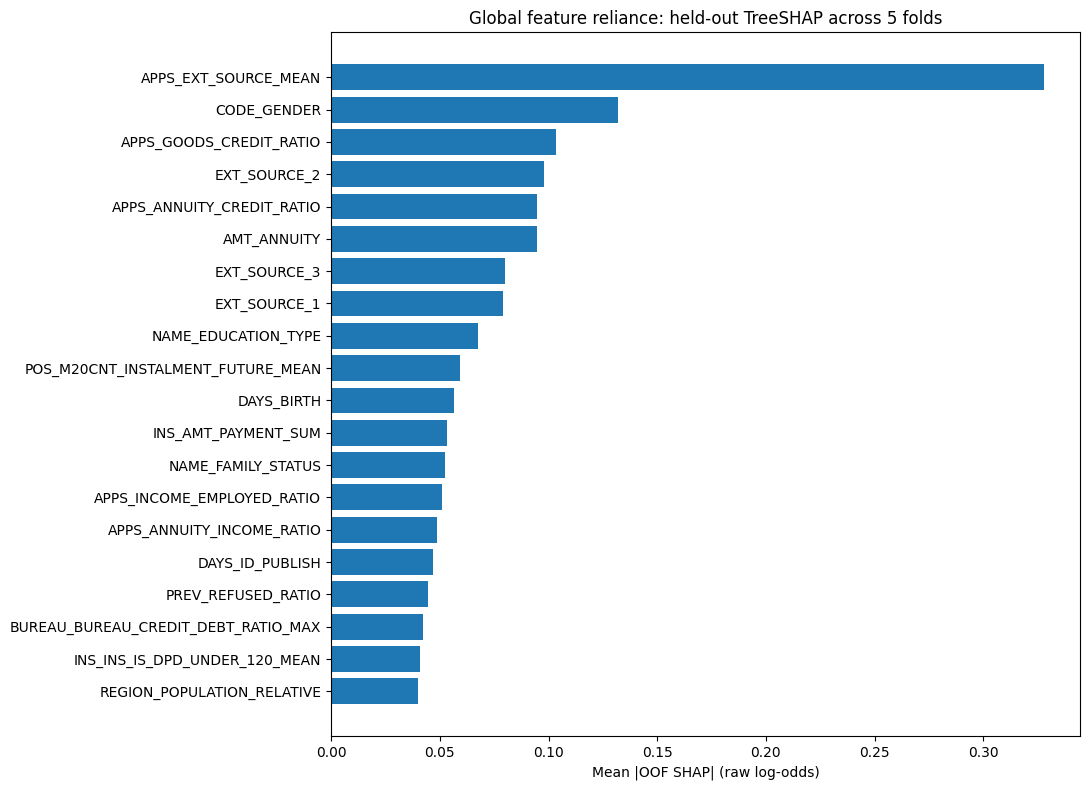

,feature_family,total_mean_abs_shap,n_features,share_of_total_abs_shap
0,Application / engineered risk scores,1.031278,16,0.243634
4,Other application fields,1.023349,118,0.241760
1,Credit bureau,0.728804,102,0.172176
3,Installment payments,0.547920,58,0.129443
6,Previous applications,0.465043,80,0.109864
5,POS / cash loans,0.280294,44,0.066218
2,Credit cards,0.156218,68,0.036906


In [19]:
# Part 1A — Exact LightGBM TreeSHAP contributions for each applicant's HELD-OUT model.
# LightGBM's pred_contrib=True returns 486 contributions + expected value.
# Contributions explain the BINARY RAW SCORE (log-odds), NOT probabilities.
n_rows, n_features = p1_sample_X.shape
p1_shap_values = np.empty((n_rows, n_features), dtype=np.float64)
p1_base_values = np.empty(n_rows, dtype=np.float64)
p1_model_risk = np.empty(n_rows, dtype=np.float64)
p1_model_margin = np.empty(n_rows, dtype=np.float64)

for fold, model in p1_models.items():
    which = np.flatnonzero(p1_sample_meta.cv_fold.to_numpy() == fold)
    X_fold = p1_sample_X.iloc[which]
    # Saved models already contain the best_iteration number of trees.
    contributions = model.predict(X_fold, pred_contrib=True, validate_features=True)
    if hasattr(contributions, 'toarray'):
        contributions = contributions.toarray()
    contributions = np.asarray(contributions)
    assert contributions.shape == (len(which), n_features + 1), (
        f'Unexpected SHAP shape for fold {fold}: {contributions.shape}'
    )
    p1_shap_values[which, :] = contributions[:, :-1]
    p1_base_values[which] = contributions[:, -1]
    p1_model_margin[which] = model.predict(X_fold, raw_score=True,
                                           validate_features=True)
    p1_model_risk[which] = model.predict(X_fold, validate_features=True)

# Guardrail: check SHAP additivity in log-odds and consistency with OOF scores.
p1_reconstructed_margin = p1_base_values + p1_shap_values.sum(axis=1)
p1_additivity_error = np.max(np.abs(p1_reconstructed_margin - p1_model_margin))
p1_sigmoid_error = np.max(np.abs(expit(p1_reconstructed_margin) - p1_model_risk))
p1_oof_error = np.max(np.abs(p1_model_risk - p1_sample_meta.oof_pred_default.to_numpy()))
print('Max |SHAP sum - model raw margin|:', p1_additivity_error)
print('Max |sigmoid(SHAP sum) - model probability|:', p1_sigmoid_error)
print('Max |fold model probability - saved OOF prediction|:', p1_oof_error)
assert p1_additivity_error < 1e-5
assert p1_sigmoid_error < 1e-7
assert p1_oof_error < 1e-6, (
    'Saved models do not reproduce Phase 0 OOF predictions. '
    'Check that the feature engineering and category factorization are unchanged.'
)

np.savez_compressed(
    PHASE1_DIR / 'oof_shap_sample.npz',
    shap_values=p1_shap_values.astype('float32'),
    base_values=p1_base_values,
    application_ids=p1_sample_meta.SK_ID_CURR.to_numpy(),
    folds=p1_sample_meta.cv_fold.to_numpy(),
    feature_names=np.asarray(ftr_app.columns, dtype=str),
)

# Model-native importance on the SAME five saved fold models for comparison.
p1_native_frames = []
for fold, model in p1_models.items():
    gain = model.feature_importance(importance_type='gain')
    splits = model.feature_importance(importance_type='split')
    p1_native_frames.append(pd.DataFrame({
        'feature': ftr_app.columns, 'fold': fold,
        'gain_share': gain / gain.sum() if gain.sum() else np.zeros_like(gain, dtype=float),
        'split_count': splits,
    }))
p1_native = pd.concat(p1_native_frames, ignore_index=True)
p1_native.to_csv(PHASE1_DIR / 'native_fold_importance.csv', index=False)
p1_native_mean = p1_native.groupby('feature', as_index=False).agg(
    mean_gain_share=('gain_share', 'mean'), mean_split_count=('split_count', 'mean'))

p1_global = pd.DataFrame({
    'feature': list(ftr_app.columns),
    'mean_abs_shap_logodds': np.mean(np.abs(p1_shap_values), axis=0),
    'mean_signed_shap_logodds': np.mean(p1_shap_values, axis=0),
    'sample_n': len(p1_sample_meta),
}).merge(p1_native_mean, on='feature', validate='one_to_one')
p1_global['shap_rank'] = p1_global.mean_abs_shap_logodds.rank(
    ascending=False, method='min').astype(int)
p1_global['gain_rank'] = p1_global.mean_gain_share.rank(
    ascending=False, method='min').astype(int)
p1_global = p1_global.sort_values('mean_abs_shap_logodds', ascending=False)
p1_global.to_csv(PHASE1_DIR / 'global_shap_vs_gain_importance.csv', index=False)
display(p1_global.head(25))

fig, ax = plt.subplots(figsize=(11, 8))
top = p1_global.head(PHASE1_TOP_N).iloc[::-1]
ax.barh(top.feature, top.mean_abs_shap_logodds)
ax.set(xlabel='Mean |OOF SHAP| (raw log-odds)',
       title='Global feature reliance: held-out TreeSHAP across 5 folds')
fig.tight_layout()
fig.savefig(PHASE1_DIR / 'global_shap_top20.png', dpi=170, bbox_inches='tight')
plt.show()

# Feature families are directional hints, not mutually exclusive or full causal taxonomies.
def p1_feature_family(name):
    if name.startswith('APPS_') or name in {'EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3'}:
        return 'Application / engineered risk scores'
    if name.startswith('PREV_'): return 'Previous applications'
    if name.startswith('BUREAU_'): return 'Credit bureau'
    if name.startswith('POS_'): return 'POS / cash loans'
    if name.startswith('INS_'): return 'Installment payments'
    if name.startswith('CARD_'): return 'Credit cards'
    return 'Other application fields'

p1_global['feature_family'] = p1_global.feature.map(p1_feature_family)
p1_families = p1_global.groupby('feature_family', as_index=False).agg(
    total_mean_abs_shap=('mean_abs_shap_logodds', 'sum'), n_features=('feature', 'count'))
p1_families['share_of_total_abs_shap'] = (p1_families.total_mean_abs_shap /
                                          p1_families.total_mean_abs_shap.sum())
p1_families.sort_values('total_mean_abs_shap', ascending=False).to_csv(
    PHASE1_DIR / 'feature_family_importance.csv', index=False)
display(p1_families.sort_values('total_mean_abs_shap', ascending=False))


### Part 1A interpretation checkpoints

Use `global_shap_vs_gain_importance.csv` as the primary model-reliance ranking. Higher mean absolute SHAP means larger average contributions to the model's **log-odds of default**. Global direction (`mean_signed_shap_logodds`) may cancel opposite effects; do not treat it as a monotonic relationship. Native gain rankings are a corroborating baseline, not a substitute for SHAP.

Specifically inspect `CODE_GENDER`, `DAYS_BIRTH`, `NAME_EDUCATION_TYPE`, `NAME_INCOME_TYPE`, `REGION_RATING_CLIENT`, `EXT_SOURCE_*`, and `APPS_EXT_SOURCE_MEAN`. Review the artificial `index` feature and unusually large ratio features. Direct and proxy associations are audit flags—not causal conclusions. Correlated derived inputs can divide attribution across features. Because categories were factorized to integer codes, the model treats them as ordered numbers; do **not** interpret code magnitude as social hierarchy.


,feature,shap_rank,gain_rank,mean_abs_shap_logodds,mean_signed_shap_logodds,mean_gain_share,mean_split_count
120,APPS_EXT_SOURCE_MEAN,1,1,0.328051,-0.001484,0.188764,1120.4
1,CODE_GENDER,2,13,0.132054,-0.001057,0.009313,334.0
40,EXT_SOURCE_2,4,3,0.098094,-0.000952,0.044447,1105.8
41,EXT_SOURCE_3,7,2,0.080067,-0.003000,0.049056,1063.4
39,EXT_SOURCE_1,8,5,0.079196,0.006188,0.017555,1271.0
11,NAME_EDUCATION_TYPE,9,17,0.067378,0.000768,0.007725,281.0
15,DAYS_BIRTH,11,7,0.056602,-0.003715,0.015029,1513.4
12,NAME_FAMILY_STATUS,13,83,0.052277,0.000346,0.002443,324.0
10,NAME_INCOME_TYPE,31,76,0.027077,-0.000916,0.002555,140.4
29,REGION_RATING_CLIENT_W_CITY,33,98,0.026497,-0.000626,0.002278,227.6


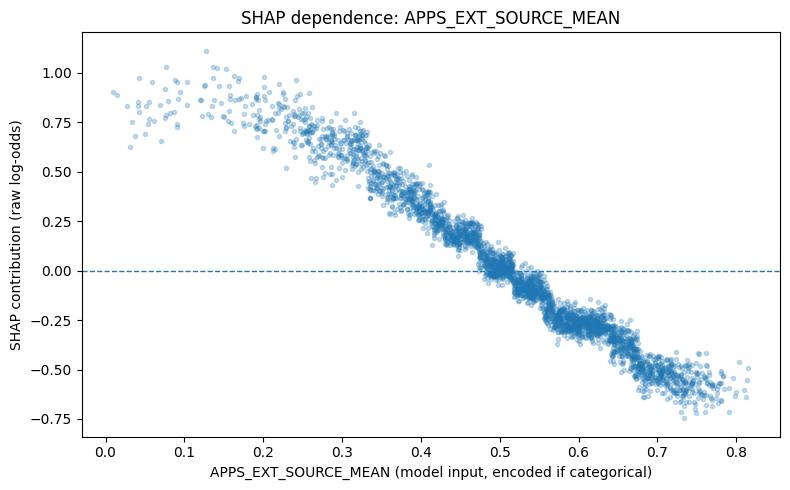

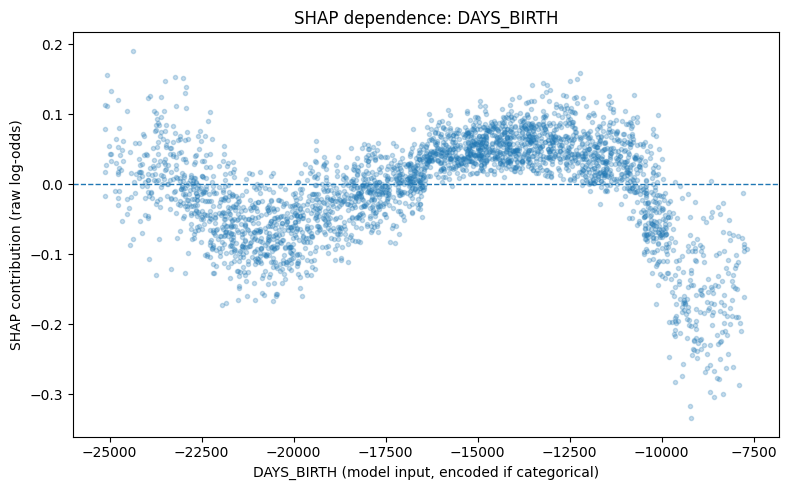

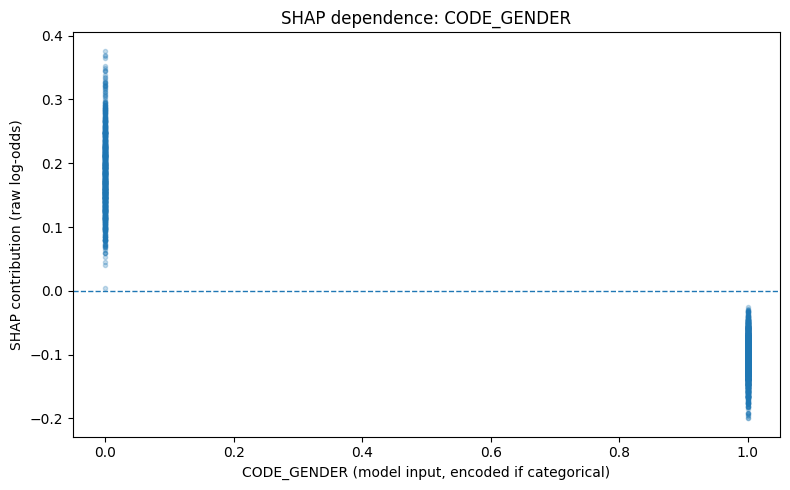

In [20]:
# Part 1A follow-up — spotlight potentially sensitive, proxy, and data-quality features.
p1_watch_features = [
    'CODE_GENDER', 'DAYS_BIRTH', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS',
    'NAME_INCOME_TYPE', 'OCCUPATION_TYPE', 'ORGANIZATION_TYPE',
    'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY',
    'AMT_INCOME_TOTAL', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3',
    'APPS_EXT_SOURCE_MEAN', 'DAYS_EMPLOYED', 'index',
]
p1_watch = p1_global[p1_global.feature.isin(p1_watch_features)].copy()
p1_watch = p1_watch[['feature', 'shap_rank', 'gain_rank',
                     'mean_abs_shap_logodds', 'mean_signed_shap_logodds',
                     'mean_gain_share', 'mean_split_count']]
p1_watch.to_csv(PHASE1_DIR / 'sensitive_proxy_watchlist.csv', index=False)
display(p1_watch)

# Lightweight exploratory scatter plots: draw from exact model inputs (NOT fake raw values).
# Extreme +/- infinity values are removed from the *display only*, never model inputs.
for name in ['APPS_EXT_SOURCE_MEAN', 'DAYS_BIRTH', 'CODE_GENDER']:
    if name not in ftr_app.columns:
        continue
    j = ftr_app.columns.get_loc(name)
    raw_x = pd.to_numeric(p1_sample_X.iloc[:, j], errors='coerce').to_numpy(dtype=float)
    finite = np.isfinite(raw_x)
    if finite.sum() < 25:
        continue
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.scatter(raw_x[finite], p1_shap_values[finite, j], s=9, alpha=0.25)
    ax.axhline(0, linestyle='--', linewidth=1)
    ax.set(xlabel=f'{name} (model input, encoded if categorical)',
           ylabel='SHAP contribution (raw log-odds)', title=f'SHAP dependence: {name}')
    fig.tight_layout()
    fig.savefig(PHASE1_DIR / f'dependence_{name.lower()}.png', dpi=155)
    plt.show()


## Phase 1B — Descriptive subgroup explanations and important individual cases

**Subgroups:** Compare distributions of *absolute* SHAP by observed raw `CODE_GENDER`, approximate age bands (from negative `DAYS_BIRTH`), and whether `EXT_SOURCE_1` is missing. Groups with fewer than 40 sampled applicants are omitted from ranked group comparisons, not treated as evidence of no effect. These results describe **which inputs drive predictions** in the selected groups; they do **not** measure equal opportunity, equalized odds, disparate impact, or causal disparate treatment. Those require separate outcome/threshold and counterfactual analyses.

**Important cases:** Use the full OOF predictions to choose 2 illustrative applicants per category: highest-risk nondefault, lowest-risk default, near-median score, and external-score missing with high risk. Labels refer to observed competition outcomes, NOT a lender approval decision. Then explain each using its held-out fold model and compare recovered probabilities with Phase 0.


Gender group sample counts (small groups excluded only from SHAP ranking):


,gender_group,n,observed_default_rate,mean_oof_risk
0,F,1935,0.070284,0.067862
1,M,1065,0.093897,0.091534


Top 10 contributors for each eligible group:


,grouping,group,n,feature,mean_abs_shap_logodds,within_group_rank
1092,age_band,30–44,1166,APPS_EXT_SOURCE_MEAN,0.309694,1
973,age_band,30–44,1166,CODE_GENDER,0.124286,2
1095,age_band,30–44,1166,APPS_GOODS_CREDIT_RATIO,0.108429,3
1094,age_band,30–44,1166,APPS_ANNUITY_CREDIT_RATIO,0.100163,4
979,age_band,30–44,1166,AMT_ANNUITY,0.098763,5
1012,age_band,30–44,1166,EXT_SOURCE_2,0.097369,6
1011,age_band,30–44,1166,EXT_SOURCE_1,0.095886,7
1013,age_band,30–44,1166,EXT_SOURCE_3,0.078222,8
983,age_band,30–44,1166,NAME_EDUCATION_TYPE,0.074894,9
1323,age_band,30–44,1166,POS_M20CNT_INSTALMENT_FUTURE_MEAN,0.054994,10


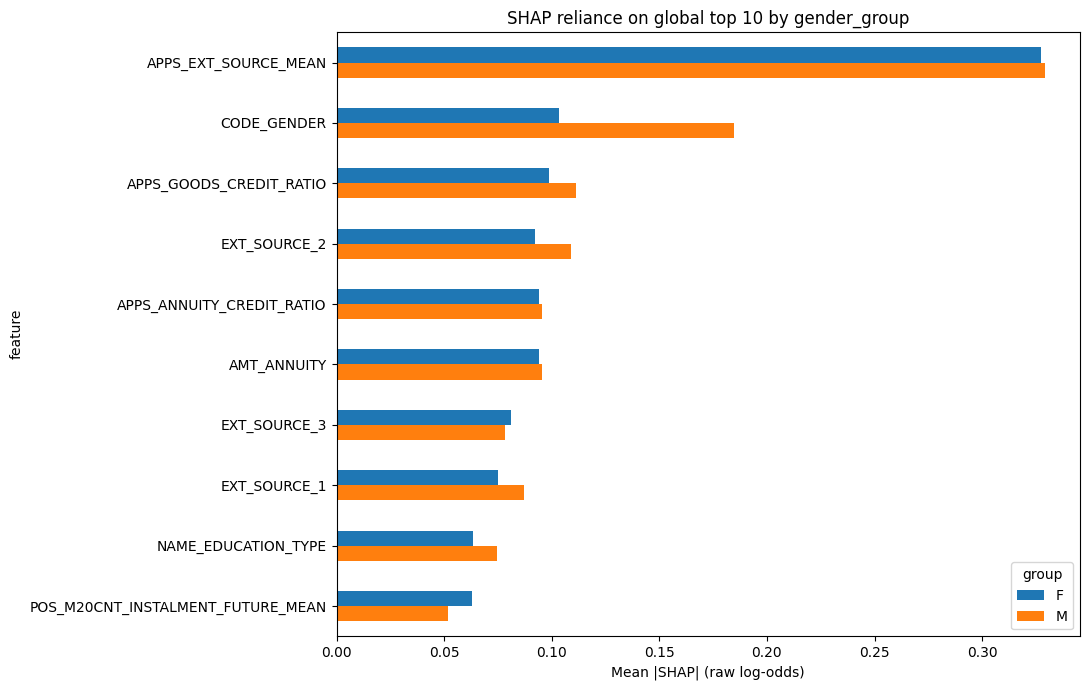

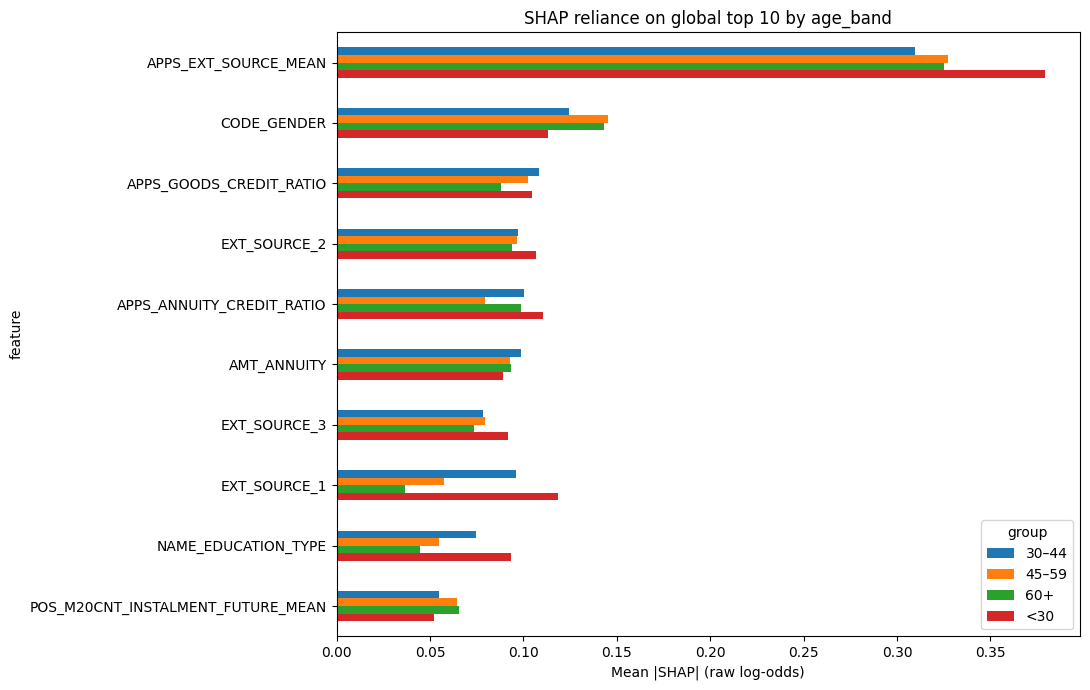

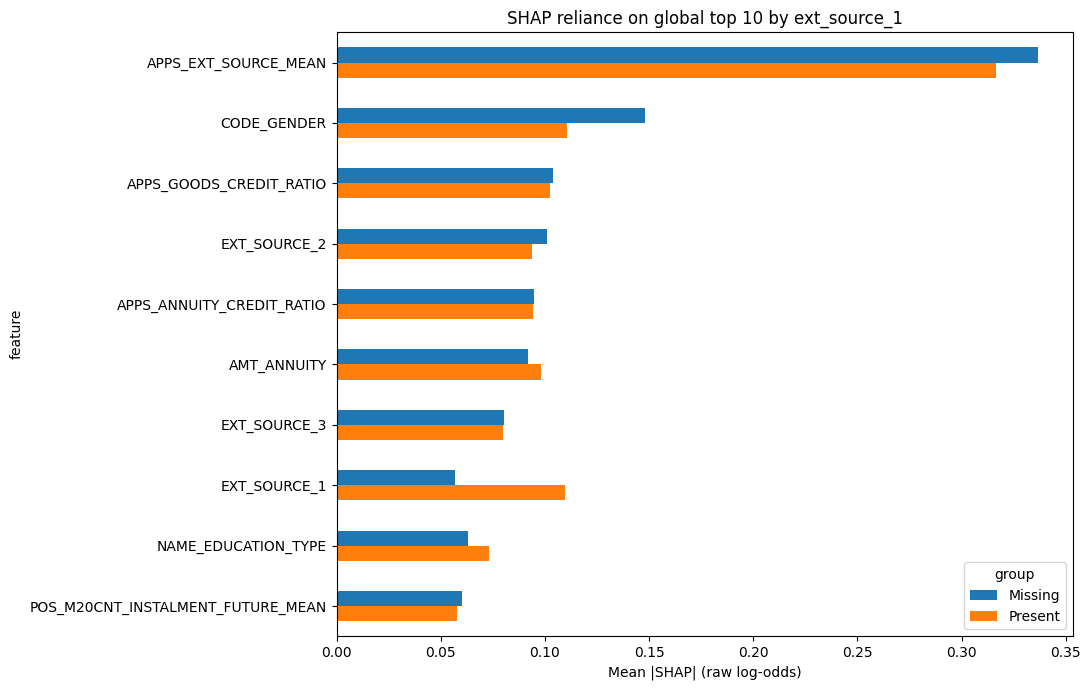

In [21]:
# Part 1B — group-conditional SHAP, aligned to raw (not factorized) attributes.
p1_groups = p1_sample_meta[['SK_ID_CURR', 'TARGET', 'cv_fold', 'oof_pred_default',
                             'CODE_GENDER', 'DAYS_BIRTH', 'EXT_SOURCE_1']].copy()
p1_groups['age_years'] = -pd.to_numeric(p1_groups['DAYS_BIRTH'], errors='coerce') / 365.25
p1_groups['age_band'] = pd.cut(
    p1_groups.age_years, [0, 30, 45, 60, 130],
    labels=['<30', '30–44', '45–59', '60+'], right=False,
).astype('string').fillna('Unknown')
p1_groups['gender_group'] = p1_groups.CODE_GENDER.astype('string').fillna('Missing')
p1_groups['ext_source_1'] = np.where(p1_groups.EXT_SOURCE_1.isna(), 'Missing', 'Present')

# Per-group mean(|SHAP|), with descriptive group sizes and actual default prevalence.
p1_group_records = []
for dimension in ['gender_group', 'age_band', 'ext_source_1']:
    for label, indices in p1_groups.groupby(dimension, observed=True).indices.items():
        if len(indices) < PHASE1_MIN_GROUP_N:
            print(f'Skipping small {dimension} group {label!r}: n={len(indices)}')
            continue
        vals = p1_shap_values[indices]
        abs_means = np.mean(np.abs(vals), axis=0)
        signed_means = np.mean(vals, axis=0)
        for feature, abs_mean, signed_mean in zip(ftr_app.columns, abs_means, signed_means):
            p1_group_records.append({
                'grouping': dimension, 'group': str(label), 'n': len(indices),
                'group_default_rate': float(p1_groups.iloc[indices].TARGET.mean()),
                'group_mean_oof_risk': float(p1_groups.iloc[indices].oof_pred_default.mean()),
                'feature': feature,
                'mean_abs_shap_logodds': float(abs_mean),
                'mean_signed_shap_logodds': float(signed_mean),
            })
p1_group_importance = pd.DataFrame(p1_group_records)
p1_group_importance['within_group_rank'] = p1_group_importance.groupby(
    ['grouping', 'group']).mean_abs_shap_logodds.rank(ascending=False, method='min').astype(int)
p1_group_importance.to_csv(PHASE1_DIR / 'subgroup_shap_importance.csv', index=False)
p1_group_top = p1_group_importance.query('within_group_rank <= 10').sort_values(
    ['grouping', 'group', 'within_group_rank'])
p1_group_top.to_csv(PHASE1_DIR / 'subgroup_top10_features.csv', index=False)

p1_group_summary = p1_groups.groupby('gender_group', dropna=False).agg(
    n=('TARGET', 'size'), observed_default_rate=('TARGET', 'mean'),
    mean_oof_risk=('oof_pred_default', 'mean')).reset_index()
print('Gender group sample counts (small groups excluded only from SHAP ranking):')
display(p1_group_summary)
print('Top 10 contributors for each eligible group:')
display(p1_group_top[['grouping','group','n','feature','mean_abs_shap_logodds',
                      'within_group_rank']].head(45))

for dim in ['gender_group', 'age_band', 'ext_source_1']:
    eligible = p1_group_importance[p1_group_importance.grouping == dim]
    if eligible.empty:
        continue
    # Compare exactly the GLOBAL top 10 features for readable across-group comparisons.
    pivot = eligible[eligible.feature.isin(p1_global.feature.head(10))].pivot(
        index='feature', columns='group', values='mean_abs_shap_logodds')
    pivot = pivot.reindex(p1_global.feature.head(10)).dropna(how='all')
    ax = pivot.plot.barh(figsize=(11, 7), title=f'SHAP reliance on global top 10 by {dim}')
    ax.set_xlabel('Mean |SHAP| (raw log-odds)')
    ax.invert_yaxis()
    plt.tight_layout()
    plt.savefig(PHASE1_DIR / f'group_shap_{dim}.png', dpi=155, bbox_inches='tight')
    plt.show()


,SK_ID_CURR,case_type,cv_fold,TARGET,oof_pred_default,shap_reconstructed_risk,base_margin_logodds,sum_shap_logodds
0,171428,high_risk_nondefault,1,0,0.788498,0.788498,-2.995013,4.310907
1,324442,high_risk_nondefault,5,0,0.785990,0.785990,-2.996785,4.297708
2,354619,low_risk_default,5,1,0.002888,0.002888,-2.996785,-2.847351
3,267336,low_risk_default,5,1,0.003661,0.003661,-2.996785,-2.609643
4,169362,near_median_risk,4,0,0.043459,0.043459,-2.969120,-0.122377
5,156641,near_median_risk,1,0,0.043459,0.043459,-2.995013,-0.096482
6,181065,high_risk_missing_ext1,1,1,0.840684,0.840684,-2.995013,4.658341
7,364859,high_risk_missing_ext1,1,1,0.837656,0.837656,-2.995013,4.635906


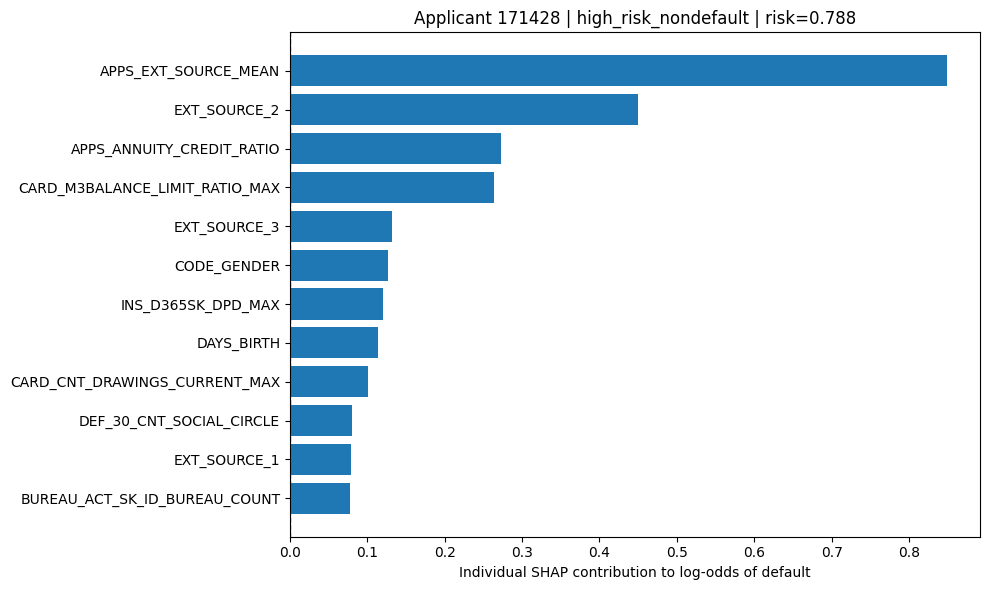

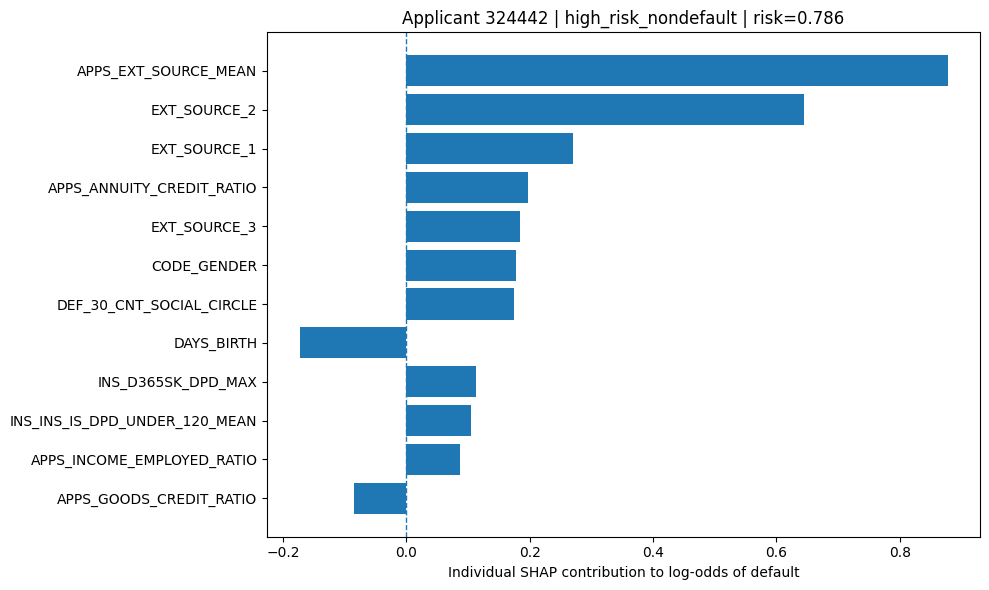

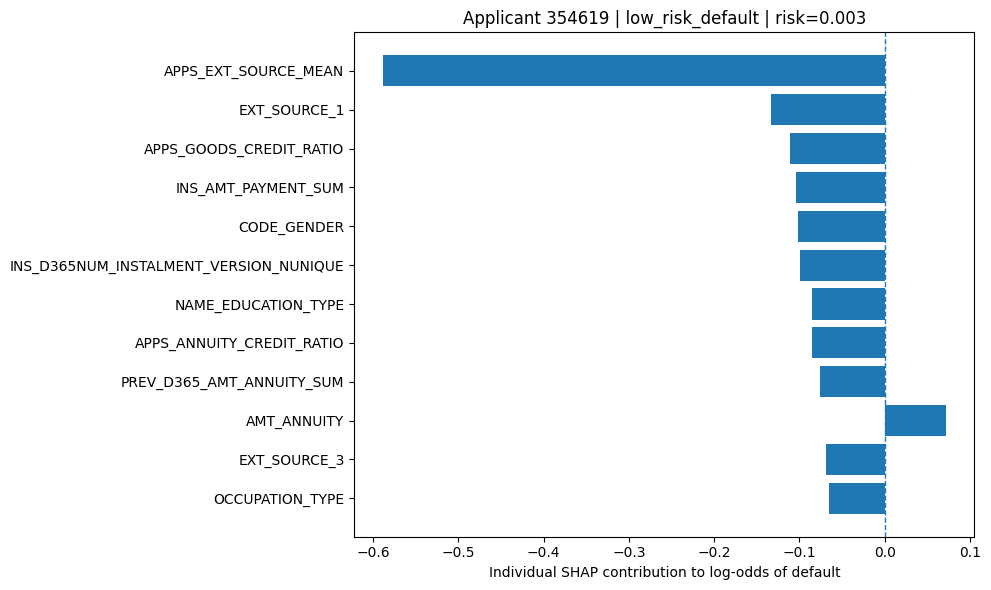

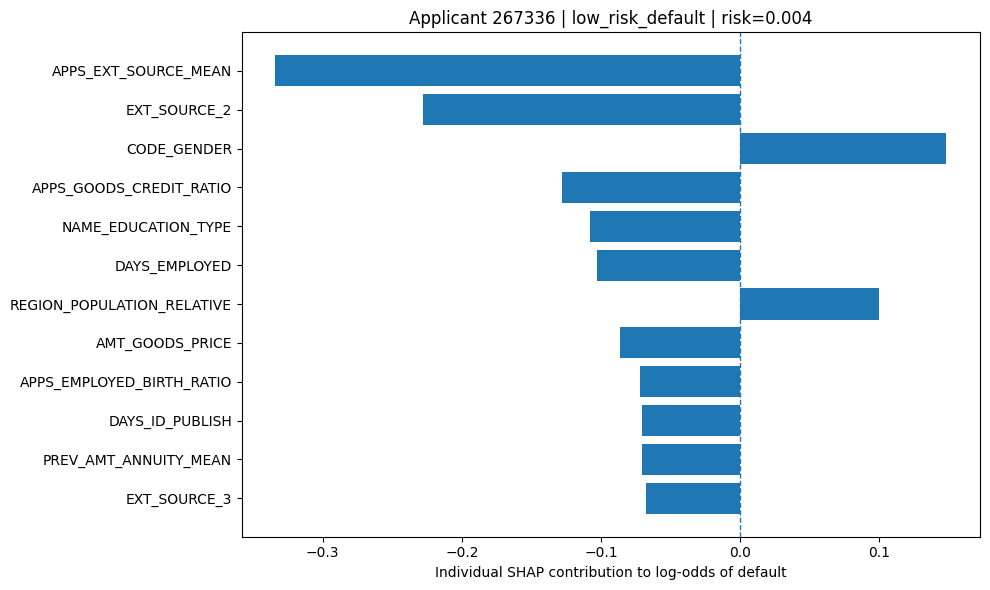

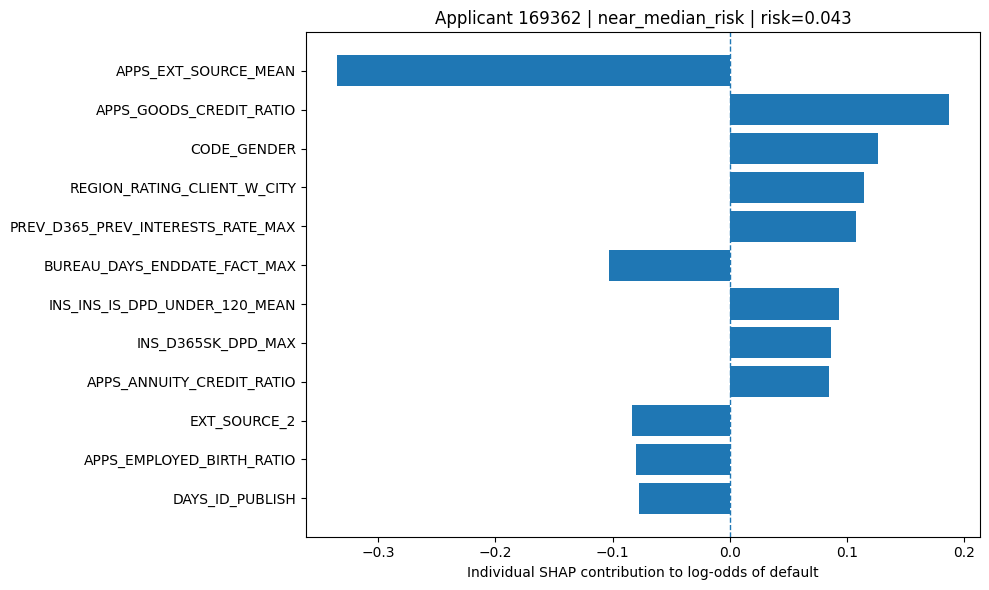

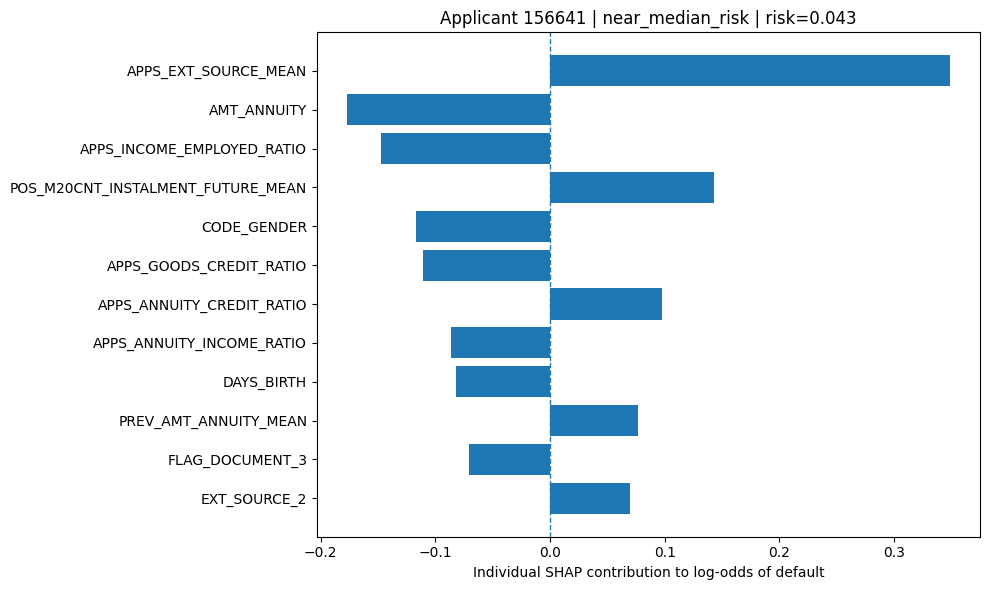

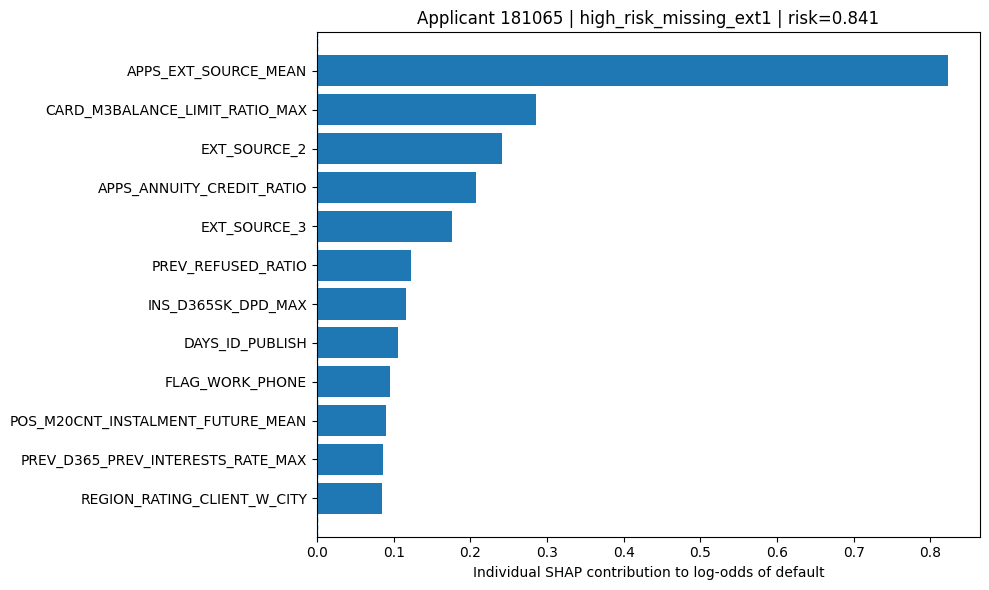

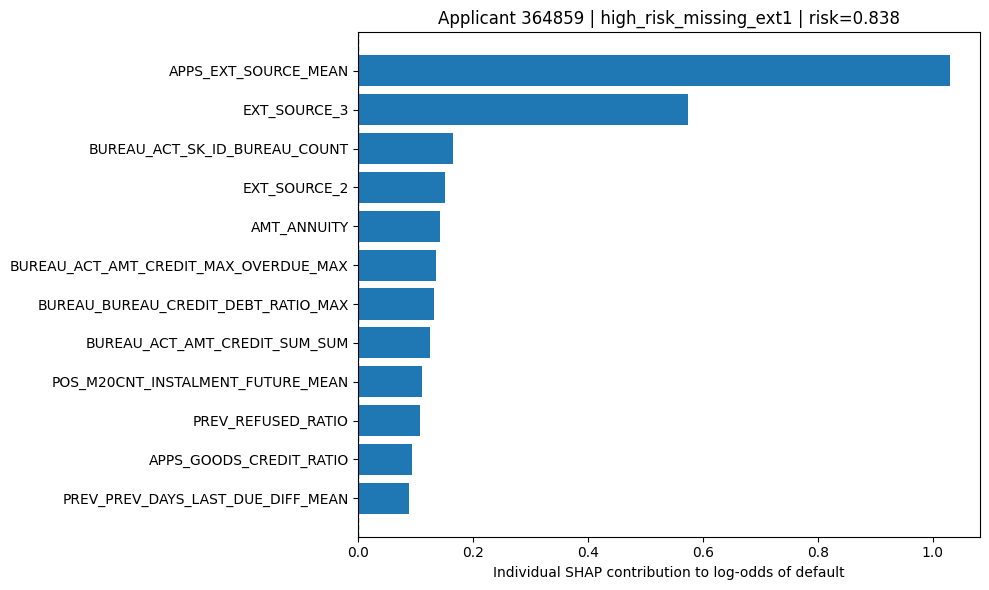

In [22]:
# Part 1B — handpicked, consequential *descriptive* cases from full OOF predictions.
# NOT loans approved/rejected: no actual lender decision threshold is known.
ranked = p1_reference.copy()
ranked['case_type'] = None
candidate_sets = {
    'high_risk_nondefault': ranked.loc[ranked.TARGET == 0].sort_values(
        'oof_pred_default', ascending=False),
    'low_risk_default': ranked.loc[ranked.TARGET == 1].sort_values(
        'oof_pred_default', ascending=True),
    'near_median_risk': ranked.assign(
        distance=(ranked.oof_pred_default - ranked.oof_pred_default.median()).abs()
    ).sort_values('distance'),
    'high_risk_missing_ext1': ranked.loc[ranked.EXT_SOURCE_1.isna()].sort_values(
        'oof_pred_default', ascending=False),
}
selected_ids = set()
p1_case_rows = []
for label, candidates in candidate_sets.items():
    for _, row in candidates.iterrows():
        key = int(row.SK_ID_CURR)
        if key in selected_ids:
            continue
        p1_case_rows.append({'SK_ID_CURR': key, 'case_type': label})
        selected_ids.add(key)
        if sum(x['case_type'] == label for x in p1_case_rows) == PHASE1_LOCAL_CASES_PER_TYPE:
            break
p1_cases = pd.DataFrame(p1_case_rows).merge(
    p1_reference, on='SK_ID_CURR', validate='one_to_one')
# Re-find feature rows *by ID* even when original data order differed.
id_to_position = pd.Series(np.arange(len(ftr_app)), index=train_application_ids.to_numpy())
p1_case_attributions = []
p1_case_summary_rows = []
for _, case in p1_cases.iterrows():
    applicant_id, fold = int(case.SK_ID_CURR), int(case.cv_fold)
    pos = int(id_to_position.loc[applicant_id])
    X_case = ftr_app.iloc[[pos]]
    booster = p1_models[fold]
    contrib = np.asarray(booster.predict(X_case, pred_contrib=True,
                                         validate_features=True))[0]
    shap_vals = contrib[:-1]
    base = float(contrib[-1])
    reconstructed_risk = float(expit(base + shap_vals.sum()))
    reference_risk = float(case.oof_pred_default)
    assert abs(reconstructed_risk - reference_risk) < 1e-6
    p1_case_summary_rows.append({
        'SK_ID_CURR': applicant_id, 'case_type': case.case_type, 'cv_fold': fold,
        'TARGET': int(case.TARGET), 'oof_pred_default': reference_risk,
        'shap_reconstructed_risk': reconstructed_risk,
        'base_margin_logodds': base,
        'sum_shap_logodds': float(shap_vals.sum()),
    })
    for j, feature in enumerate(ftr_app.columns):
        p1_case_attributions.append({
            'SK_ID_CURR': applicant_id, 'case_type': case.case_type,
            'feature': feature, 'shap_logodds': float(shap_vals[j]),
            'abs_shap_logodds': float(abs(shap_vals[j])),
            'model_feature_value': str(X_case.iloc[0, j]),
        })
p1_case_summary = pd.DataFrame(p1_case_summary_rows)
p1_local = pd.DataFrame(p1_case_attributions)
p1_local['rank_within_case'] = p1_local.groupby('SK_ID_CURR').abs_shap_logodds.rank(
    ascending=False, method='min').astype(int)
p1_case_summary.to_csv(PHASE1_DIR / 'local_case_manifest.csv', index=False)
p1_local.to_csv(PHASE1_DIR / 'local_shap_all_features.csv', index=False)
p1_local.query('rank_within_case <= 15').sort_values(
    ['SK_ID_CURR', 'rank_within_case']).to_csv(
    PHASE1_DIR / 'local_shap_top15.csv', index=False)

display(p1_case_summary)
for _, case in p1_case_summary.iterrows():
    df = p1_local[p1_local.SK_ID_CURR == case.SK_ID_CURR].nlargest(12, 'abs_shap_logodds')
    df = df.iloc[::-1]
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(df.feature, df.shap_logodds)
    ax.axvline(0, linestyle='--', linewidth=1)
    ax.set(xlabel='Individual SHAP contribution to log-odds of default',
           title=f"Applicant {case.SK_ID_CURR} | {case.case_type} | risk={case.oof_pred_default:.3f}")
    fig.tight_layout()
    fig.savefig(PHASE1_DIR / f'local_{case.SK_ID_CURR}.png', dpi=155, bbox_inches='tight')
    plt.show()


In [23]:
# Phase 1A/B audit record — outputs generated only after successful explanation checks.
p1_run_manifest = {
    'source_phase0': str(PHASE0_DIR),
    'phase1_output_dir': str(PHASE1_DIR),
    'sample_seed': PHASE1_SEED,
    'per_fold_sample_limit': PHASE1_SAMPLE_PER_FOLD,
    'sample_n': len(p1_sample_meta),
    'n_features': len(ftr_app.columns),
    'n_local_cases': len(p1_case_summary),
    'shap_unit': 'raw binary margin (log-odds of TARGET=1)',
    'shap_algorithm': 'LightGBM exact tree-path-dependent pred_contrib; held-out fold models',
    'max_additivity_error_raw_margin': float(p1_additivity_error),
    'max_fold_model_vs_saved_oof_probability_error': float(p1_oof_error),
    'small_group_threshold': PHASE1_MIN_GROUP_N,
    'caveats': [
        'Descriptive interpretation, not a causal fairness test',
        'Feature matrix recreated with original eight-file preprocessing',
        'OOF folds use validation labels for early stopping',
        'Nominal categories are ordinal-coded in original model',
        'Inf, missing values, DAYS_EMPLOYED sentinel and index artifact were not changed',
        'No real lender decision threshold is available',
        'Globally sampled held-out explanations; local examples intentionally extreme',
    ],
}
(PHASE1_DIR / 'phase1_ab_complete.json').write_text(
    json.dumps(p1_run_manifest, indent=2), encoding='utf-8')
print('Phase 1A/B run passed fidelity checks.')
print('Saved all results to:', PHASE1_DIR.resolve())
print('Suggested write-up: Global top drivers, direct sensitive use and proxies,')
print('subgroup attribution differences with n, and illustrative case explanations.')
print('Later ablations: drop accidental index, sanitize ±infinity ratios,')
print('treat nominal codes categorically, evaluate employment sentinel,')
print('and use a separate early-stopping holdout for unbiased evaluation.')


Phase 1A/B run passed fidelity checks.
Saved all results to: /content/audit_artifacts/phase1
Suggested write-up: Global top drivers, direct sensitive use and proxies,
subgroup attribution differences with n, and illustrative case explanations.
Later ablations: drop accidental index, sanitize ±infinity ratios,
treat nominal codes categorically, evaluate employment sentinel,
and use a separate early-stopping holdout for unbiased evaluation.


I used ChatGPT to help write parts of the code in this notebook.